<a href="https://colab.research.google.com/github/Dan-KM/is-project-2/blob/feature%2Fmode_integration/app/model/colab/Irrigation_prediction_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Irrigation Action Prediction: Model Training.

This notebook trains the classifier behind the irrigation decision support system.
Given a field's crop, soil and weather readings, it recommends one of four
irrigation actions: `No_Irrigation`, `Low`, `Medium` or `High`.

The saved pipeline (preprocessing + model) is served by a FastAPI service and
called by the farmer app. Every decision in this notebook therefore has to match
what the app can actually send: the same feature names, the same category
spellings and the same units.

**Structure**

1. Environment setup
2. Load data
3. Exploratory data analysis (EDA)
4. Train/test split
5. Feature selection
6. Preprocessing pipeline
7. Baseline models and cross-validation
8. Hyperparameter tuning
9. Final evaluation on the test set
10. Explainability
11. Model persistence and contract test

## 1. Environment setup

### 1.1 Detect the environment

The notebook can run in Google Colab or on a local machine, and each needs a
different set of dependencies. We first work out which environment we are in.

- `python-dotenv` reads a local `.env` file, so a local run can set
  `ENVIRONMENT` explicitly (for example `ENVIRONMENT=DEV`).
- In Colab there is no `.env` file, so Colab is detected automatically from
  the loaded modules.
- Anything unrecognised falls back to `DEV`, the safest default.

In [147]:
%pip install -q python-dotenv

In [148]:
import os
import sys
from dotenv import load_dotenv

# override=True: values in .env take precedence over existing OS variables
load_dotenv(override=True)

VALID_ENVIRONMENTS = {"PROD", "STAGING", "TESTING", "COLAB", "DEV"}


def resolve_environment():
    if os.environ.get("ENVIRONMENT"):
        return os.environ["ENVIRONMENT"].upper()
    if "google.colab" in sys.modules:
        return "COLAB"
    return "DEV"


ENV_SETUP = resolve_environment()
if ENV_SETUP not in VALID_ENVIRONMENTS:
    print(f"Warning: invalid ENVIRONMENT '{ENV_SETUP}'. Defaulting to 'DEV'.")
    ENV_SETUP = "DEV"

print(f"Environment: {ENV_SETUP}")

Environment: COLAB


### 1.2 Install dependencies

Each environment has its own requirements file. A single lookup table replaces
the five near-identical `if/elif` branches of the earlier draft: adding an
environment now means adding one line, and there is no risk of the branches
drifting apart.

The constraints file pins exact versions for local runs. This matters because
the saved model must later be loaded by the FastAPI service with the **same**
scikit-learn version it was trained with.

In [149]:
import subprocess

REQ_BASE = "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements"
CONSTRAINTS = ["-c", f"{REQ_BASE}/constraints.txt"]

REQUIREMENTS = {
    "PROD":    [f"{REQ_BASE}/prod.txt"],
    "STAGING": [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
    "TESTING": [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
    "COLAB":   [f"{REQ_BASE}/colab.txt"],
    "DEV":     [f"{REQ_BASE}/dev.txt", *CONSTRAINTS],
}

In [150]:
def silent_pip_install(args):
    """Run pip quietly and print output only if it fails."""
    # sys.executable makes sure we install into the running kernel's environment
    cmd = [sys.executable, "-m", "pip", "install", *args]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr)


silent_pip_install(["-r", *REQUIREMENTS[ENV_SETUP]])
print(f"Dependencies installed for '{ENV_SETUP}'.")

Dependencies installed for 'COLAB'.


### 1.3 Imports and display settings

Only the libraries used throughout the notebook are imported here. Modelling
libraries (scikit-learn estimators, SHAP, LIME) are imported in the step that
uses them, so each step can be read on its own.

Warnings are hidden to keep the outputs readable. While you are debugging a
cell, comment that line out so that nothing important is hidden.

In [151]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

### 1.4 Project constants

Values used in many cells are defined **once**, here. The earlier draft
redefined some of them later (`TARGET`, the class order, `numeric_cols`), which
let cells silently disagree depending on the order they were run in.

| Constant | Why it exists |
|---|---|
| `RANDOM_STATE` | Fixed seed, so the split, the CV folds and the models are reproducible. |
| `TARGET` | The column we predict. |
| `ID_COL` | `Field_ID` only identifies a field. It says nothing about irrigation need, so it is never used as a feature. |
| `CLASS_ORDER` | The natural order of the actions, from none to high. Plots and confusion matrices use it; alphabetical order would put `High` first. |
| `DATASET_URL`, `DATASET_PATH` | Where the data comes from, and where it is cached locally. |

In [152]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET = "Irrigation_Action"
ID_COL = "Field_ID"
CLASS_ORDER = ["No_Irrigation", "Low", "Medium", "High"]

DATASET_URL = "https://raw.githubusercontent.com/Dan-KM/is-project-2/refs/heads/main/dataset/Irrigation_Scheduling_Dataset.csv"
DATASET_PATH = "./data/Irrigation_Scheduling_Dataset.csv"

## 2. Load data

The dataset is downloaded once from the project repository and cached in
`./data`, so re-running the cell does not download it again. Note that Colab
clears `./data` when the runtime restarts, so the first run of a new session
always downloads it.

In [153]:
import urllib.request

if os.path.exists(DATASET_PATH):
    print("Dataset already exists locally.")
else:
    os.makedirs(os.path.dirname(DATASET_PATH), exist_ok=True)
    urllib.request.urlretrieve(DATASET_URL, DATASET_PATH)
    print("Dataset downloaded.")

df = pd.read_csv(DATASET_PATH, encoding="utf-8")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Dataset already exists locally.
Shape: 7000 rows x 27 columns


,Field_ID,Crop_Type,Growth_Stage,Soil_Type,Day_of_Year,Time_of_Day,Soil_Moisture,Soil_Temperature,Soil_pH,Soil_EC,Ambient_Temperature,Relative_Humidity,Wind_Speed,Solar_Radiation,Rainfall_24h,Rainfall_Forecast_24h,Root_Zone_Depth,Leaf_Area_Index,Crop_Coefficient,Field_Slope,Water_Availability,Previous_Irrigation_Amount,Days_Since_Last_Irrigation,Historical_Soil_Moisture,Evaporation_Demand,Water_Stress_Index,Irrigation_Action
0,52,Wheat,Flowering,Clay,306,16,34.653372,28.475039,7.22,1.63,25.162077,75.883860,2.059025,617.894746,1.66,11.78,35.23,4.19,1.15,4.86,65.38,10.50,7,24.66,52.41,76.23,Medium
1,93,Rice,Maturity,Sandy,89,13,33.868557,23.155641,6.57,1.28,26.570275,88.786710,0.149411,459.057124,0.07,8.59,45.76,1.52,0.75,6.56,27.17,43.60,3,29.82,36.76,72.15,High
2,15,Groundnut,Fruiting,Clay,155,14,42.952956,23.344024,7.57,2.21,33.783657,75.959237,3.395399,456.585275,1.43,34.49,49.14,3.94,1.05,7.16,79.06,12.54,10,40.47,43.20,71.10,No_Irrigation
3,72,Wheat,Vegetative,Loamy,233,14,34.452554,29.874891,7.20,1.00,28.060771,71.470308,2.169183,583.682496,17.07,1.70,21.74,3.47,0.90,7.37,82.31,12.90,12,22.52,45.19,72.61,Medium
4,61,Sugarcane,Flowering,Sandy,193,14,20.163457,29.949118,6.24,1.78,25.205416,68.243676,5.644328,570.043475,2.72,2.86,45.94,4.41,1.15,5.16,77.28,4.12,11,15.32,50.08,93.57,High


In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Field_ID                    7000 non-null   int64  
 1   Crop_Type                   7000 non-null   object 
 2   Growth_Stage                7000 non-null   object 
 3   Soil_Type                   7000 non-null   object 
 4   Day_of_Year                 7000 non-null   int64  
 5   Time_of_Day                 7000 non-null   int64  
 6   Soil_Moisture               6965 non-null   float64
 7   Soil_Temperature            6965 non-null   float64
 8   Soil_pH                     7000 non-null   float64
 9   Soil_EC                     7000 non-null   float64
 10  Ambient_Temperature         7000 non-null   float64
 11  Relative_Humidity           6965 non-null   float64
 12  Wind_Speed                  7000 non-null   float64
 13  Solar_Radiation             6965 

**Reading the output**

- 7,000 rows and 27 columns: `Field_ID`, 25 candidate predictors and the target.
- Six columns have 35 missing values each (0.5%): `Soil_Moisture`,
  `Soil_Temperature`, `Relative_Humidity`, `Solar_Radiation`, `Rainfall_24h` and
  `Historical_Soil_Moisture`. Every other column is complete.
- Three predictors are text (`Crop_Type`, `Growth_Stage`, `Soil_Type`), as is
  the target.

**Decision:** no rows are dropped. Missing values are filled in inside the
preprocessing pipeline (section 6). This matters because the app will also send
incomplete readings, and the pipeline must handle them in exactly the same way
at prediction time.

### 2.1 Target variable

The target is `Irrigation_Action`. The check below makes sure the dataset uses
exactly the four labels in `CLASS_ORDER`. If a label were misspelled (say,
`No irrigation`), the assertion stops the notebook here instead of letting a
fifth "class" leak into training.

In [155]:
actual_classes = set(df[TARGET].unique())
assert actual_classes == set(CLASS_ORDER), f"Unexpected labels: {actual_classes ^ set(CLASS_ORDER)}"

n_predictors = df.shape[1] - 2  # everything except ID_COL and TARGET
print(f"Target: {TARGET}")
print(f"Classes (natural order): {CLASS_ORDER}")
print(f"Candidate predictors: {n_predictors}")

Target: Irrigation_Action
Classes (natural order): ['No_Irrigation', 'Low', 'Medium', 'High']
Candidate predictors: 25


### 2.2 Data dictionary: units and ranges

A model learns from numbers, not units. Suppose it is trained on a feature
measured as a percentage, and the app later sends the same feature in litres.
The model then receives values far outside anything it has seen, and its
predictions become meaningless **without any error being raised**.

The dataset ([Kaggle: Irrigation Scheduling Dataset](https://www.kaggle.com/datasets/datcolabssnet/irrigation-scheduling-dataset))
does not document its units, and it appears to be synthetic. We therefore
infer each feature's unit from its observed range and compare it with what the
app sends.

In [156]:
numeric_features = df.select_dtypes(include="number").columns.drop(ID_COL)

feature_ranges = pd.DataFrame({
    "min": df[numeric_features].min(),
    "q1": df[numeric_features].quantile(0.25),
    "median": df[numeric_features].median(),
    "q3": df[numeric_features].quantile(0.75),
    "max": df[numeric_features].max(),
    "missing": df[numeric_features].isna().sum(),
}).round(2)

feature_ranges

,min,q1,median,q3,max,missing
Day_of_Year,1.00,88.00,181.00,272.00,365.00,0
Time_of_Day,0.00,5.00,11.00,17.00,23.00,0
Soil_Moisture,7.90,29.30,34.99,40.40,64.83,35
Soil_Temperature,11.96,22.09,25.03,27.87,39.65,35
Soil_pH,5.00,6.32,6.69,7.07,8.20,0
Soil_EC,0.25,0.96,1.26,1.57,2.78,0
Ambient_Temperature,14.83,25.58,29.02,32.33,45.16,0
Relative_Humidity,44.69,69.75,75.20,80.46,98.08,35
Wind_Speed,-0.02,1.86,3.20,4.96,15.13,0
Solar_Radiation,49.74,399.61,521.75,642.95,950.23,35


**Reading the output: inferred units compared with the app**

| Feature | Training range | Inferred dataset unit | App sends | Status |
|---|---|---|---|---|
| `Day_of_Year` | 1 – 365 | day of year | day of year (Nairobi) | OK |
| `Time_of_Day` | 0 – 23 | hour | hour (Nairobi) | OK |
| `Soil_Moisture` | 7.9 – 64.8 | % | % (farmer reading) | OK |
| `Soil_Temperature` | 12.0 – 39.7 | °C | °C | OK |
| `Soil_pH` | 5.0 – 8.2 | pH | pH | OK |
| `Soil_EC` | 0.25 – 2.78 | dS/m | dS/m | OK |
| `Ambient_Temperature` | 14.8 – 45.2 | °C | °C | OK |
| `Relative_Humidity` | 44.7 – 98.1 | % | % | OK |
| `Wind_Speed` | -0.02 – 15.1 | m/s | m/s | OK (a negative speed is noise) |
| `Solar_Radiation` | 49.7 – 950.2 | W/m², instantaneous | MJ/m²/day, daily total | **Mismatch** |
| `Rainfall_24h` | 0 – 81.4 | mm | mm | OK |
| `Rainfall_Forecast_24h` | 0 – 105.8 | mm | mm | OK |
| `Root_Zone_Depth` | 15 – 80 | cm | m (database) | **Convert** |
| `Leaf_Area_Index` | 0.35 – 6.14 | m²/m² | m²/m² | OK |
| `Crop_Coefficient` | 0.65 – 1.15 | Kc | Kc | OK |
| `Field_Slope` | 0.2 – 8.0 | % (assumed) | % | OK |
| `Water_Availability` | 10 – 100, most often 100 | % (how full) | litres remaining | **Mismatch** |
| `Previous_Irrigation_Amount` | 0.15 – 45 | mm of water depth | litres | **Convert** |
| `Days_Since_Last_Irrigation` | 0 – 14 | days | days, no upper limit | **Clip** |
| `Historical_Soil_Moisture` | 5.0 – 66.4 | % | % (7-day average) | OK |
| `Evaporation_Demand` | 2.0 – 97.7, median 45.7 | unknown index | ET₀ in mm/day | **Mismatch** |
| `Water_Stress_Index` | 24.9 – 100 | index | never sent | Dropped (section 5) |

Most features already match. Five need handling: four mismatches, plus one
range clip.

**Decision: train on the dataset's scale, convert in the app**

The model is trained on the data exactly as it is. The app converts its values
to the training scale before sending them. This keeps the notebook faithful to
the data, and it puts each conversion next to the source it depends on: the
database, the weather API or the water ledger.

| Feature | Conversion done by the app | Why |
|---|---|---|
| `Root_Zone_Depth` | metres × 100 → cm | The database stores metres; 0.15–0.80 m maps exactly onto the 15–80 cm range. |
| `Previous_Irrigation_Amount` | litres ÷ (field area in ha × 10,000) → mm | 1 litre spread over 1 m² is 1 mm of water, so this is an exact conversion, not an estimate. |
| `Water_Availability` | remaining budget ÷ budget at the last top-up × 100 → % | The 10–100 range, most often exactly 100, reads as "how full". A budget that has just been topped up is 100%. |
| `Solar_Radiation` | Open-Meteo *current* shortwave radiation (W/m²), clipped to 0 – 1,100, then mapped linearly onto 49.7 – 950.2: `49.7 + x / 1100 × (950.2 − 49.7)` | Same instantaneous unit as the dataset. The API's full range (0 at night, about 1,100 W/m² at a clear equatorial noon) is mapped range-to-range onto the training range, so night becomes the training minimum rather than a value the model has never seen. |
| `Evaporation_Demand` | **Not sent (dropped)** | The unit is undocumented, so any conversion from ET₀ would be a guess. Section 5 compares cross-validated scores with and without it, so the cost of dropping it is measured. |
| `Days_Since_Last_Irrigation` | values above 14 are sent as 14 | The model has never seen more than 14 days; "14 or more" is the safest reading. |

**Stated limitations (for the thesis)**

- The dataset is synthetic and undocumented, so the units above are inferred
  from value ranges, not confirmed.
- `Evaporation_Demand` is a strong predictor (section 3), but its unit cannot
  be matched to anything the app measures. It is dropped rather than fed a
  guessed conversion. Section 5 reports how much accuracy this costs.
- The `Solar_Radiation` mapping compresses daytime values slightly (for
  example, 600 W/m² is sent as about 541). This is accepted because the
  dataset's unit is itself only inferred, so matching ranges is as defensible
  as matching raw values, and it handles night consistently.
- `feature_ranges` is saved with the model (section 11). The API can then flag
  any value outside the training range instead of silently trusting it.

## 3. Exploratory data analysis (EDA)

EDA is about understanding the data before modelling it: how the classes are
balanced, how each feature is distributed, which features relate to the
target, and which features repeat each other. Each subsection ends with a
**conclusion** and the **decision** it leads to.

EDA uses the full dataset because it only *describes* the data. No feature is
kept or dropped here. Those decisions are made in section 5 on the training
set only, so the test set never influences the model.

### 3.1 Class balance

**Why:** the class balance decides two things: which metric is fair, and
whether we need resampling techniques such as SMOTE. If one class dominated,
a model could score well just by always predicting it.

In [157]:
class_summary = pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "proportion": df[TARGET].value_counts(normalize=True).round(3),
}).loc[CLASS_ORDER]

class_summary

,count,proportion
Irrigation_Action,,
No_Irrigation,1750,0.25
Low,1750,0.25
Medium,1750,0.25
High,1750,0.25


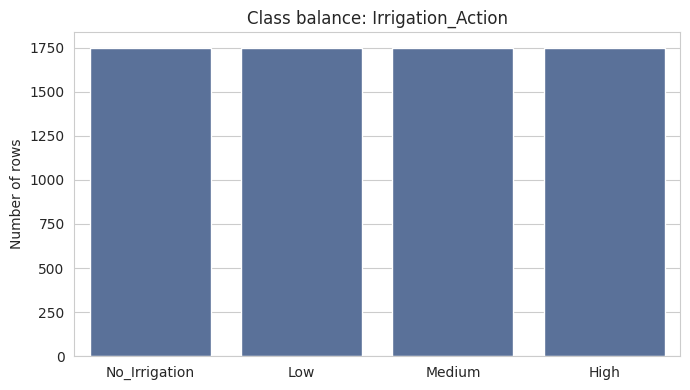

In [158]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=TARGET, order=CLASS_ORDER, color="#4F6EA4")
plt.title("Class balance: Irrigation_Action")
plt.ylabel("Number of rows")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Conclusion:** the classes are perfectly balanced: 1,750 rows each (25%).

**Decisions:**
- **No resampling.** SMOTE, ADASYN and undersampling exist to fix imbalance,
  and there is none to fix. Synthetic rows would only add noise. The earlier
  draft used SMOTE everywhere; it is removed from section 7 onwards.
- **The bar to beat is 25%.** A model that guesses at random, or always
  predicts one class, scores about 25%. Section 7 measures this with a dummy
  model so every real model can be compared against it.
- **Macro-F1 is the main metric.** It weighs every class equally. On balanced
  data it behaves like accuracy, but it stays fair if real farm data turns out
  to be imbalanced.
- **The train/test split is stratified** (section 4), so both sets keep the
  25% balance.

### 3.2 Distribution of the numeric features

**Why:** skewed features (a long tail on one side) can dominate distance-based
and linear models, and features on very different scales need standardising.
This subsection decides which transforms the preprocessing pipeline needs
(section 6).

- **Skewness** near 0 means symmetric; above about 1 (or below -1) means a
  strong tail.
- **Kurtosis** (excess) above 0 means heavier tails than a normal
  distribution, so more extreme values.

In [159]:
distribution_summary = pd.DataFrame({
    "mean": df[numeric_features].mean(),
    "std": df[numeric_features].std(),
    "skewness": df[numeric_features].skew(),
    "kurtosis": df[numeric_features].kurt(),
}).round(2)

distribution_summary.sort_values("skewness", key=abs, ascending=False)

,mean,std,skewness,kurtosis
Rainfall_Forecast_24h,8.76,13.94,3.37,12.23
Rainfall_24h,7.47,12.33,3.35,11.82
Wind_Speed,3.72,2.52,1.31,2.24
Previous_Irrigation_Amount,13.86,9.45,1.09,0.92
Crop_Coefficient,0.95,0.17,-0.34,-1.10
Leaf_Area_Index,2.99,1.10,-0.25,-0.49
Water_Stress_Index,75.53,12.21,-0.19,-0.11
Soil_Moisture,34.63,8.33,-0.19,-0.09
Water_Availability,67.91,17.71,-0.19,-0.40
Historical_Soil_Moisture,30.84,9.75,-0.08,-0.21


**Conclusion:**
- `Rainfall_24h` and `Rainfall_Forecast_24h` are strongly right-skewed
  (skewness about 3.4, kurtosis about 12). Most days have little rain, and a
  few have a lot.
- `Wind_Speed` (1.3) and `Previous_Irrigation_Amount` (1.1) are moderately
  skewed.
- Every other feature is close to symmetric (|skewness| < 0.35).
- Scales differ widely: `Solar_Radiation` is in the hundreds, while
  `Soil_EC` is around 1.
- The most common value of `Water_Availability` is exactly its maximum (100),
  and the same holds for `Previous_Irrigation_Amount` (45). The data generator
  capped these values, which is another sign that the dataset is synthetic.

**Decisions (applied in section 6):**
- Rainfall gets a **Yeo-Johnson** transform to pull in the long tail.
  Yeo-Johnson is used instead of Box-Cox because rainfall contains zeros, and
  Box-Cox only accepts values above 0.
- The moderately skewed features are revisited in section 6, but only if they
  survive feature selection.
- Numeric features are **standardised**. Tree models do not need it, but
  logistic regression, KNN and SVM do, and we compare all of them.

### 3.3 Outliers

**Why:** extreme values can be data errors, which should be removed, or real
but rare events, which should be kept. We flag them using the **IQR rule**: a
value is an outlier if it lies more than 1.5 × IQR below the first quartile
or above the third quartile.

In [160]:
q1 = df[numeric_features].quantile(0.25)
q3 = df[numeric_features].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_mask = (df[numeric_features] < lower_fence) | (df[numeric_features] > upper_fence)
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

outlier_counts[outlier_counts > 0].to_frame("outlier_count")

,outlier_count
Crop_Coefficient,807
Rainfall_24h,642
Rainfall_Forecast_24h,625
Wind_Speed,217
Previous_Irrigation_Amount,217
Ambient_Temperature,64
Soil_Moisture,46
Soil_pH,45
Relative_Humidity,39
Water_Stress_Index,37


The plots below show the six most-flagged features. On the left is the
distribution with the fences marked. On the right is the same feature split
by irrigation action, which shows whether the extreme values belong to a
particular class.

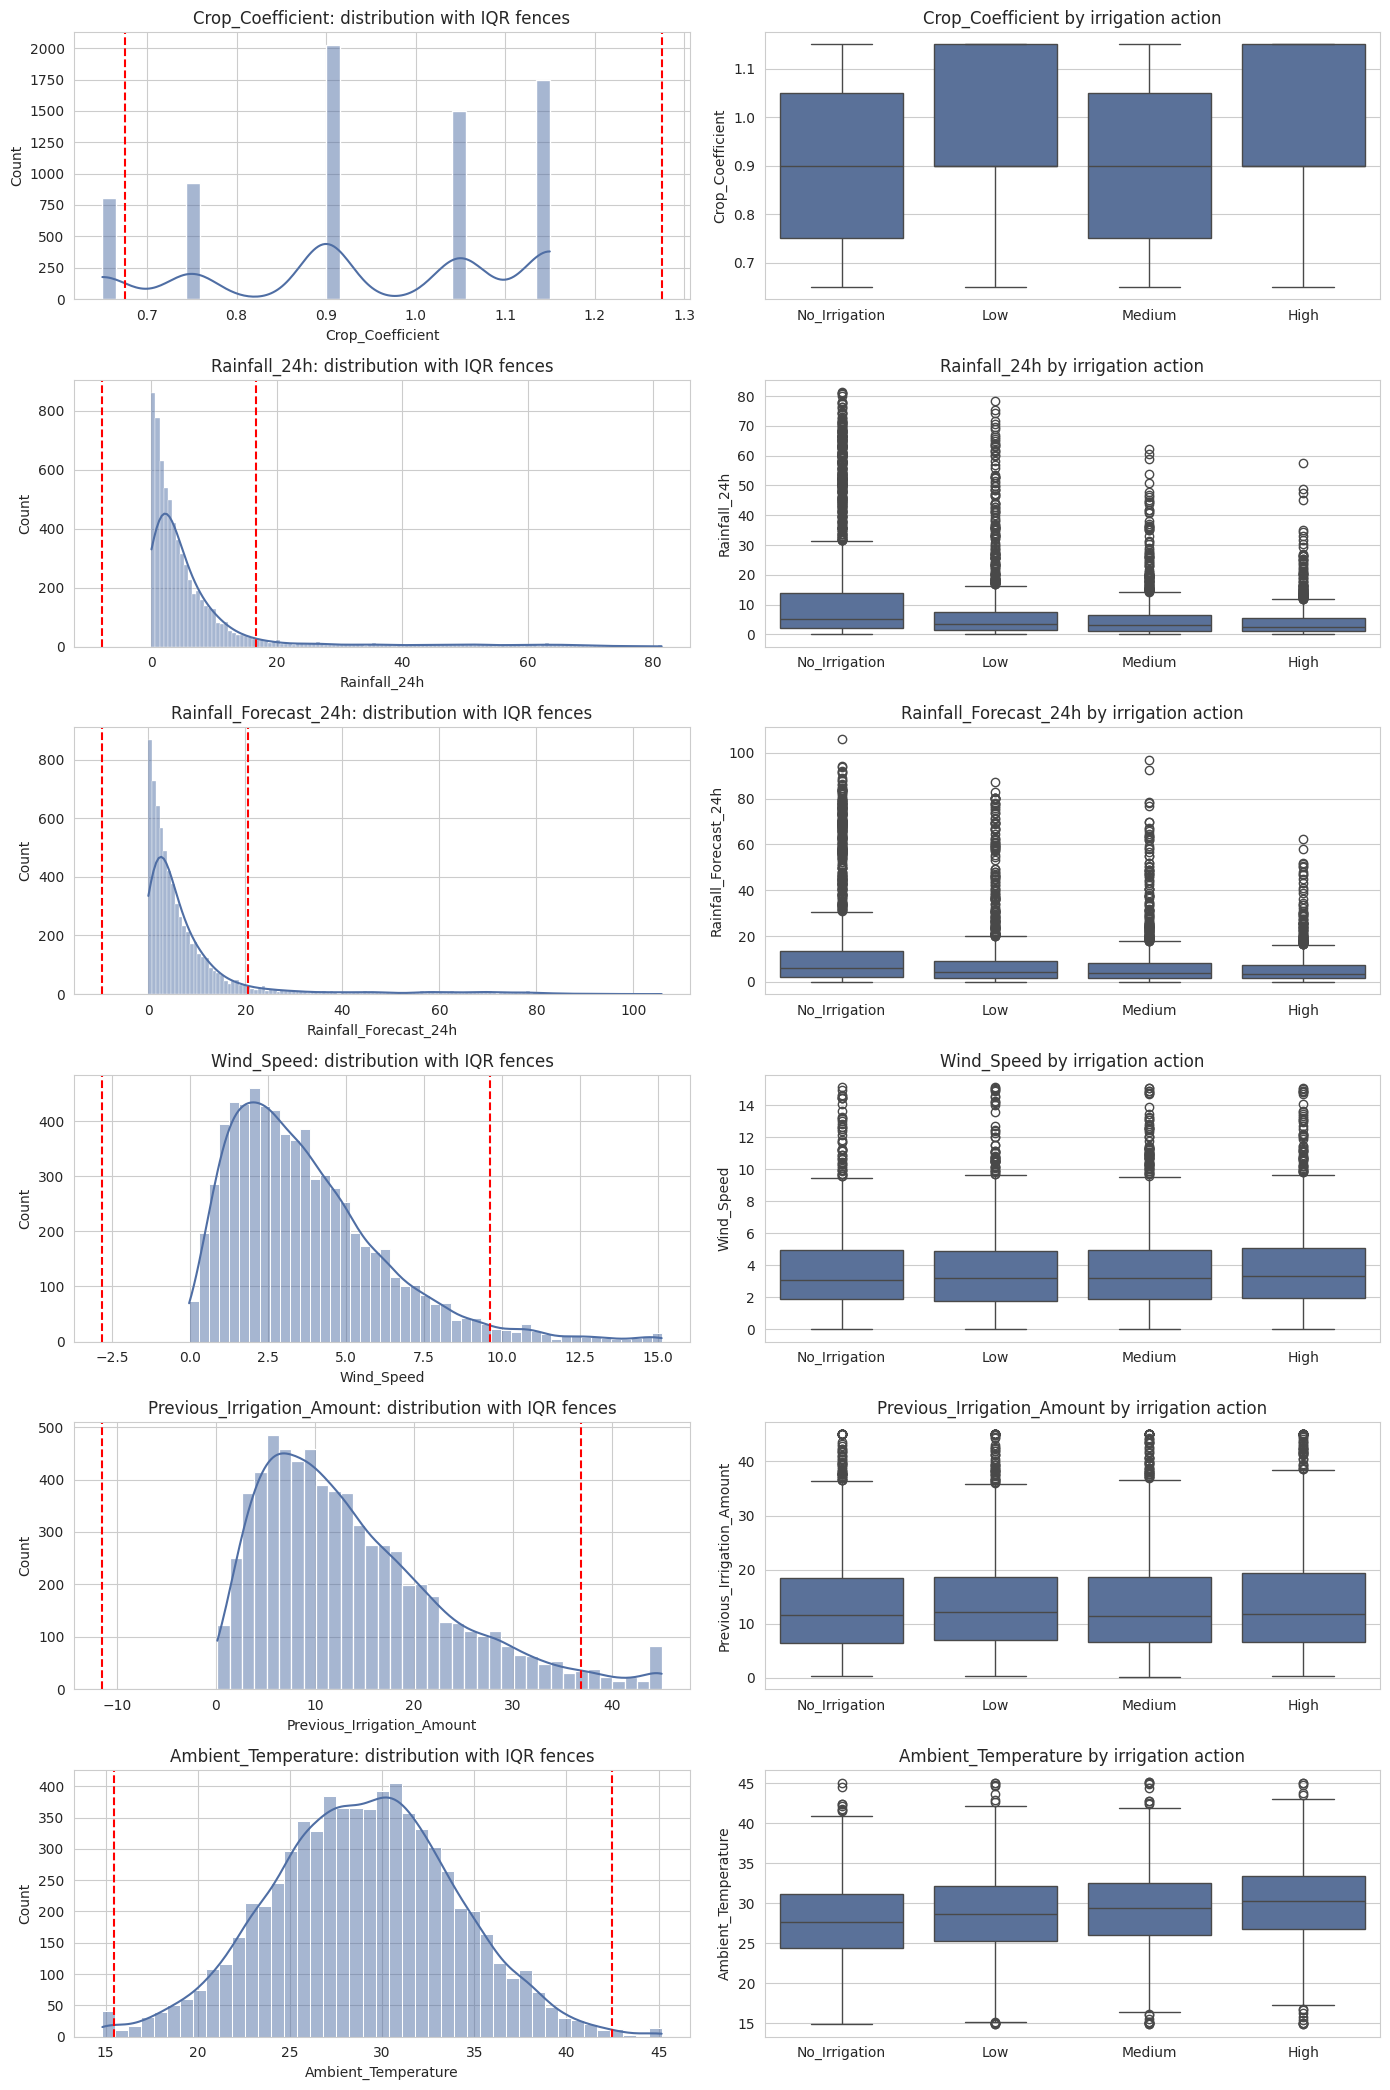

In [161]:
most_flagged = outlier_counts.index[:6]

fig, axes = plt.subplots(len(most_flagged), 2, figsize=(14, 3.5 * len(most_flagged)))

for row, col in enumerate(most_flagged):
    sns.histplot(df[col], kde=True, ax=axes[row, 0], color="#4F6EA4")
    axes[row, 0].axvline(lower_fence[col], color="red", linestyle="--")
    axes[row, 0].axvline(upper_fence[col], color="red", linestyle="--")
    axes[row, 0].set_title(f"{col}: distribution with IQR fences")

    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, ax=axes[row, 1], color="#4F6EA4")
    axes[row, 1].set_title(f"{col} by irrigation action")
    axes[row, 1].set_xlabel("")

plt.tight_layout()
plt.show()

In [162]:
# A physically impossible value: wind speed cannot be negative
negative_wind = df.loc[df["Wind_Speed"] < 0, "Wind_Speed"]
print(f"Negative wind speeds: {len(negative_wind)} rows, lowest = {negative_wind.min()}")

Negative wind speeds: 4 rows, lowest = -0.0202845927525143


**Conclusion:**
- The flagged values are the **long tails of skewed features** (rainfall,
  wind, previous irrigation), not errors. A day with 80 mm of rain is rare but
  real, and it is exactly the case where the model should say `No_Irrigation`.
- `Crop_Coefficient` is flagged most often, but only because Kc takes a few
  fixed values (it comes from crop/stage tables). At least a quarter of the rows sit at exactly 0.90, so
  the IQR is narrow, and the legitimate value 0.65 falls outside it.
- The only impossible values are a few slightly negative wind speeds (a
  minimum of -0.02 m/s), which is tiny noise from the data generator.

**Decision:** **no rows are removed.** Removing real extremes would delete the
most informative cases. Tree models are not affected by extreme values, and
the transforms in section 6 handle the skew for the other models. The
negative wind speeds are too small to matter, and the app never sends a
negative value.

### 3.4 Relationship between each feature and the target

**Why:** this is the first indication of which features carry information
about the irrigation action. Three tests are used because each sees something
different:

| Test | Applies to | Detects |
|---|---|---|
| ANOVA F-test | numeric features | differences in class *means* (linear) |
| Cramér's V | categorical features | association between two categorical variables |
| Mutual information | all features | any dependence, including non-linear |

A feature that scores low on all three is a weak candidate for the model.

#### 3.4.1 ANOVA F-test (numeric features)

**The ANOVA F-statistic tests whether the mean of a numeric feature differs
across the four classes.** It compares the variance *between* the class
groups with the variance *within* each group.

- **F-statistic:** higher means the class means are more clearly separated.
  A value near 0 means no separation.
- **p-value:** the probability of an F this large if the feature had no real
  relationship with the target. Below 0.05 is taken as evidence of a genuine
  association.

The test cannot handle missing values, so they are temporarily filled with the
median. This is for the diagnostic only; the real imputation happens inside
the pipeline. The test only sees linear differences in means, so it is a
first screen, not a final decision.

In [163]:
from sklearn.feature_selection import f_classif

numeric_filled = df[numeric_features].fillna(df[numeric_features].median())
f_stats, p_values = f_classif(numeric_filled, df[TARGET])

anova_summary = pd.DataFrame(
    {"F_statistic": f_stats, "p_value": p_values},
    index=numeric_features,
).sort_values("F_statistic", ascending=False)

anova_summary.round(4)

,F_statistic,p_value
Water_Stress_Index,1904.0791,0.0000
Soil_Moisture,865.3713,0.0000
Historical_Soil_Moisture,617.1364,0.0000
Evaporation_Demand,317.5209,0.0000
Rainfall_24h,238.3719,0.0000
Solar_Radiation,236.7714,0.0000
Rainfall_Forecast_24h,139.1866,0.0000
Ambient_Temperature,69.0100,0.0000
Relative_Humidity,41.6727,0.0000
Water_Availability,17.5446,0.0000


**Conclusion:**
- **Strong:** `Water_Stress_Index` (F ≈ 1,904), `Soil_Moisture` (865),
  `Historical_Soil_Moisture` (617), `Evaporation_Demand` (318), `Rainfall_24h`
  (238), `Solar_Radiation` (237) and `Rainfall_Forecast_24h` (139).
- **Moderate:** `Ambient_Temperature` (69), `Relative_Humidity` (42) and
  `Water_Availability` (18).
- **No significant difference (p > 0.05):** `Soil_Temperature`, `Wind_Speed`,
  `Time_of_Day`, `Day_of_Year`, `Field_Slope`, `Previous_Irrigation_Amount`,
  `Root_Zone_Depth`, `Soil_EC` and `Soil_pH`.

This agrees with irrigation practice: water need is driven by how wet the soil
is, how fast it dries (sun, heat) and how much rain falls or is coming.

#### 3.4.2 Cramér's V (categorical features)

Cramér's V measures the strength of association between a categorical feature
and the categorical target, based on the chi-square statistic. It ranges from
0 to 1 whatever the number of categories, so the features are comparable.

| Value | Association |
|---|---|
| 0.00 – 0.10 | negligible |
| 0.10 – 0.20 | weak |
| 0.20 – 0.40 | moderate |
| 0.40 and above | strong |

The version below uses **Bergsma's bias correction**, because the plain
formula slightly overstates association.

In [164]:
def cramers_v(contingency_table):
    """Bias-corrected Cramer's V for a contingency table (counts)."""
    chi2_stat = stats.chi2_contingency(contingency_table)[0]
    n = contingency_table.sum()
    r, k = contingency_table.shape

    phi2 = chi2_stat / n
    phi2_corrected = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corrected = r - (r - 1) ** 2 / (n - 1)
    k_corrected = k - (k - 1) ** 2 / (n - 1)

    return np.sqrt(phi2_corrected / min(k_corrected - 1, r_corrected - 1))

In [165]:
categorical_features = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()

cramers_v_summary = pd.Series(
    {col: cramers_v(pd.crosstab(df[col], df[TARGET]).values) for col in categorical_features},
    name="Cramers_V",
).sort_values(ascending=False).round(3)

cramers_v_summary.to_frame()

,Cramers_V
Soil_Type,0.219
Crop_Type,0.031
Growth_Stage,0.012


The chart below shows, for each category, the share of each irrigation action.
If a feature had no effect, every bar would look the same (25% each).

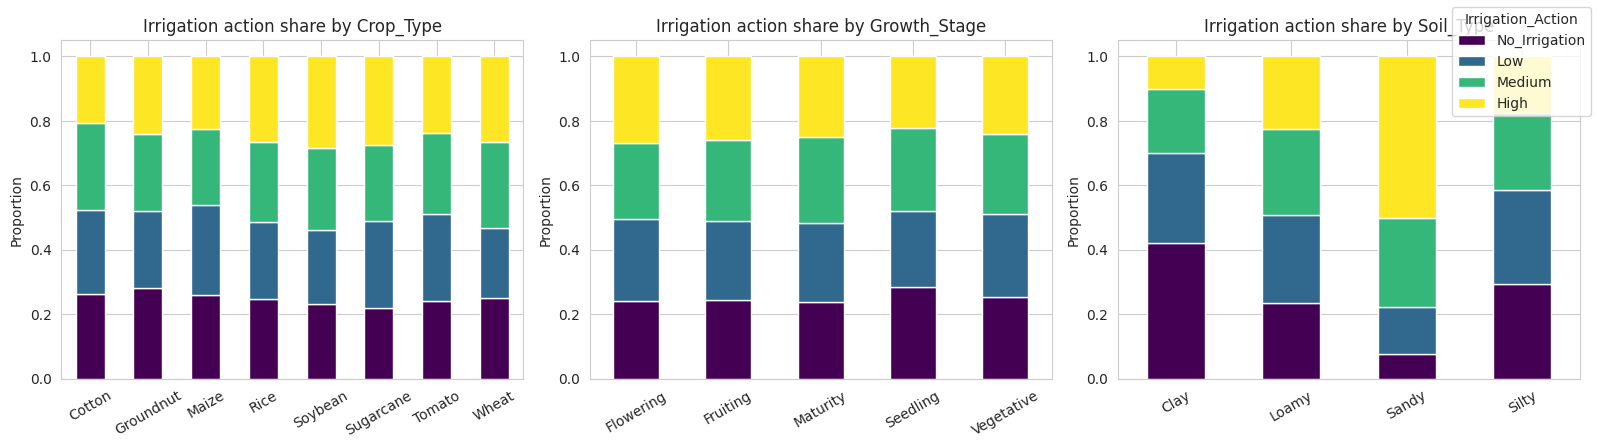

In [166]:
fig, axes = plt.subplots(1, len(categorical_features), figsize=(16, 4.5))

for ax, col in zip(axes, categorical_features):
    shares = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_ORDER]
    shares.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="viridis")
    ax.set_title(f"Irrigation action share by {col}")
    ax.set_ylabel("Proportion")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title=TARGET, loc="upper right")
plt.tight_layout()
plt.show()

**Conclusion:**
- **`Soil_Type` has a moderate association (V ≈ 0.22).** On sandy soil about
  half of the rows are `High` and very few are `No_Irrigation`. On clay it is
  the reverse. This matches soil physics: sand drains quickly and holds
  little water, while clay holds water for longer.
- **`Crop_Type` (0.03) and `Growth_Stage` (0.01) are negligible.** Their bars
  are almost identical across categories. Note that the earlier draft called
  0.22 "weak"; on the scale above it is moderate.

**Decision:** `Soil_Type` is a clear keep. `Crop_Type` and `Growth_Stage` look
uninformative in this dataset, but the app always sends them and agronomy
says they matter. Section 5 tests whether keeping them helps or hurts.

#### 3.4.3 Mutual information (all features)

Mutual information (MI) measures how much knowing a feature reduces
uncertainty about the target. Unlike ANOVA, it also detects non-linear
relationships, and it handles numeric and categorical features on one scale.
An MI of 0 means the feature tells us nothing about the target.

Categorical features are passed as integer codes and flagged as *discrete*,
so MI treats them as categories rather than as numbers.

In [167]:
from sklearn.feature_selection import mutual_info_classif

mi_input = numeric_filled.copy()
for col in categorical_features:
    mi_input[col] = df[col].astype("category").cat.codes

is_discrete = [col in categorical_features for col in mi_input.columns]

mi_scores = pd.Series(
    mutual_info_classif(mi_input, df[TARGET], discrete_features=is_discrete, random_state=RANDOM_STATE),
    index=mi_input.columns,
).sort_values()

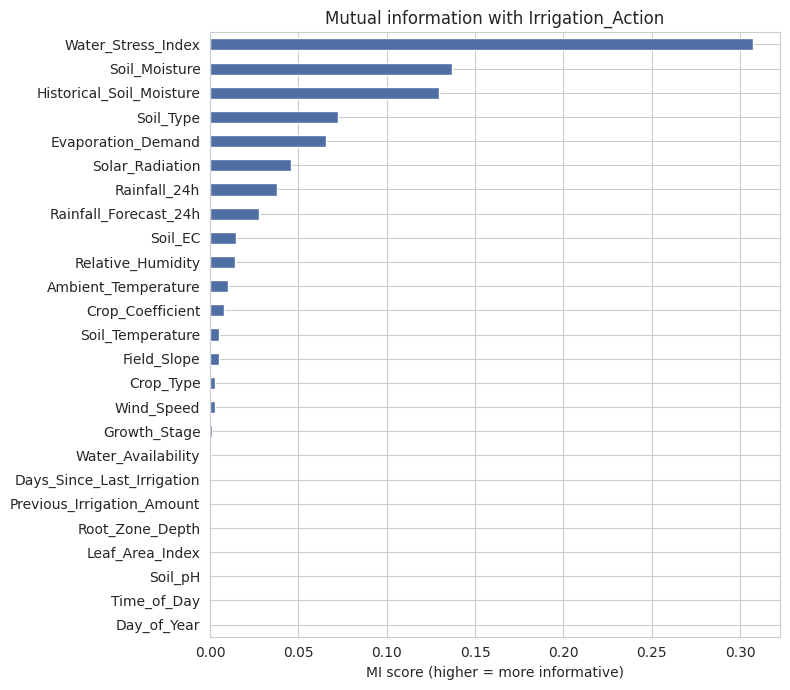

In [168]:
mi_scores.plot(kind="barh", figsize=(8, 7), color="#4F6EA4")
plt.title("Mutual information with Irrigation_Action")
plt.xlabel("MI score (higher = more informative)")
plt.tight_layout()
plt.show()

**Conclusion:** MI agrees with ANOVA on the top of the ranking:
`Water_Stress_Index`, `Soil_Moisture`, `Historical_Soil_Moisture`, then
`Soil_Type`, `Evaporation_Demand`, `Solar_Radiation` and rainfall. No feature
that ANOVA called weak turns out to have a strong non-linear relationship.
`Field_Slope`, `Root_Zone_Depth`, `Previous_Irrigation_Amount`, `Soil_pH`,
`Time_of_Day` and `Day_of_Year` score about 0 on MI as well, so they are weak
on every test.

### 3.5 Feature profiles by irrigation action

**Why:** the tests above give one number per feature. The profiles show *how*
a feature changes from `No_Irrigation` to `High`, and how much the classes
overlap. That overlap tells us how hard the problem is.

Features are standardised (z-scores) so they can share one colour scale:
0 is the overall average, and ±1 is one standard deviation.

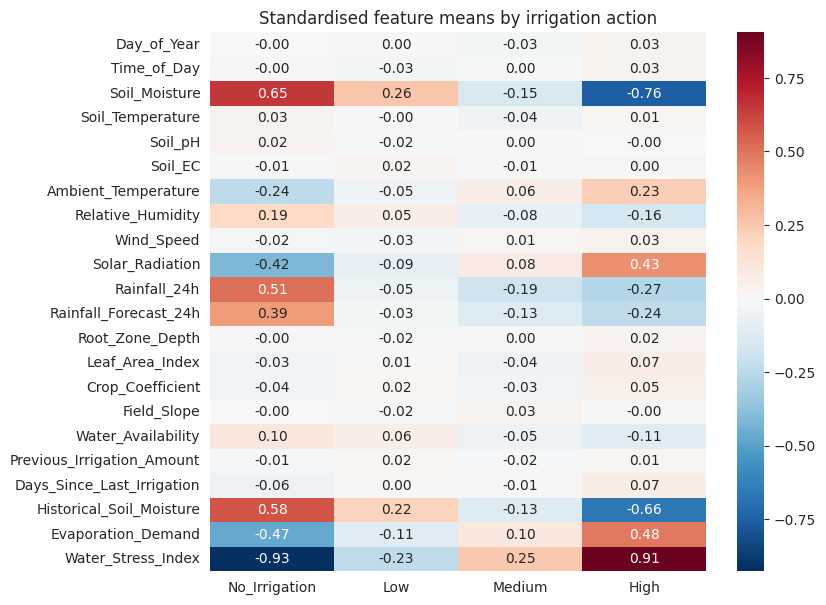

In [169]:
z_scores = (df[numeric_features] - df[numeric_features].mean()) / df[numeric_features].std()
z_scores[TARGET] = df[TARGET]

class_profile = z_scores.groupby(TARGET)[numeric_features].mean().T[CLASS_ORDER]

plt.figure(figsize=(8, 7))
sns.heatmap(class_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Standardised feature means by irrigation action")
plt.xlabel("")
plt.show()

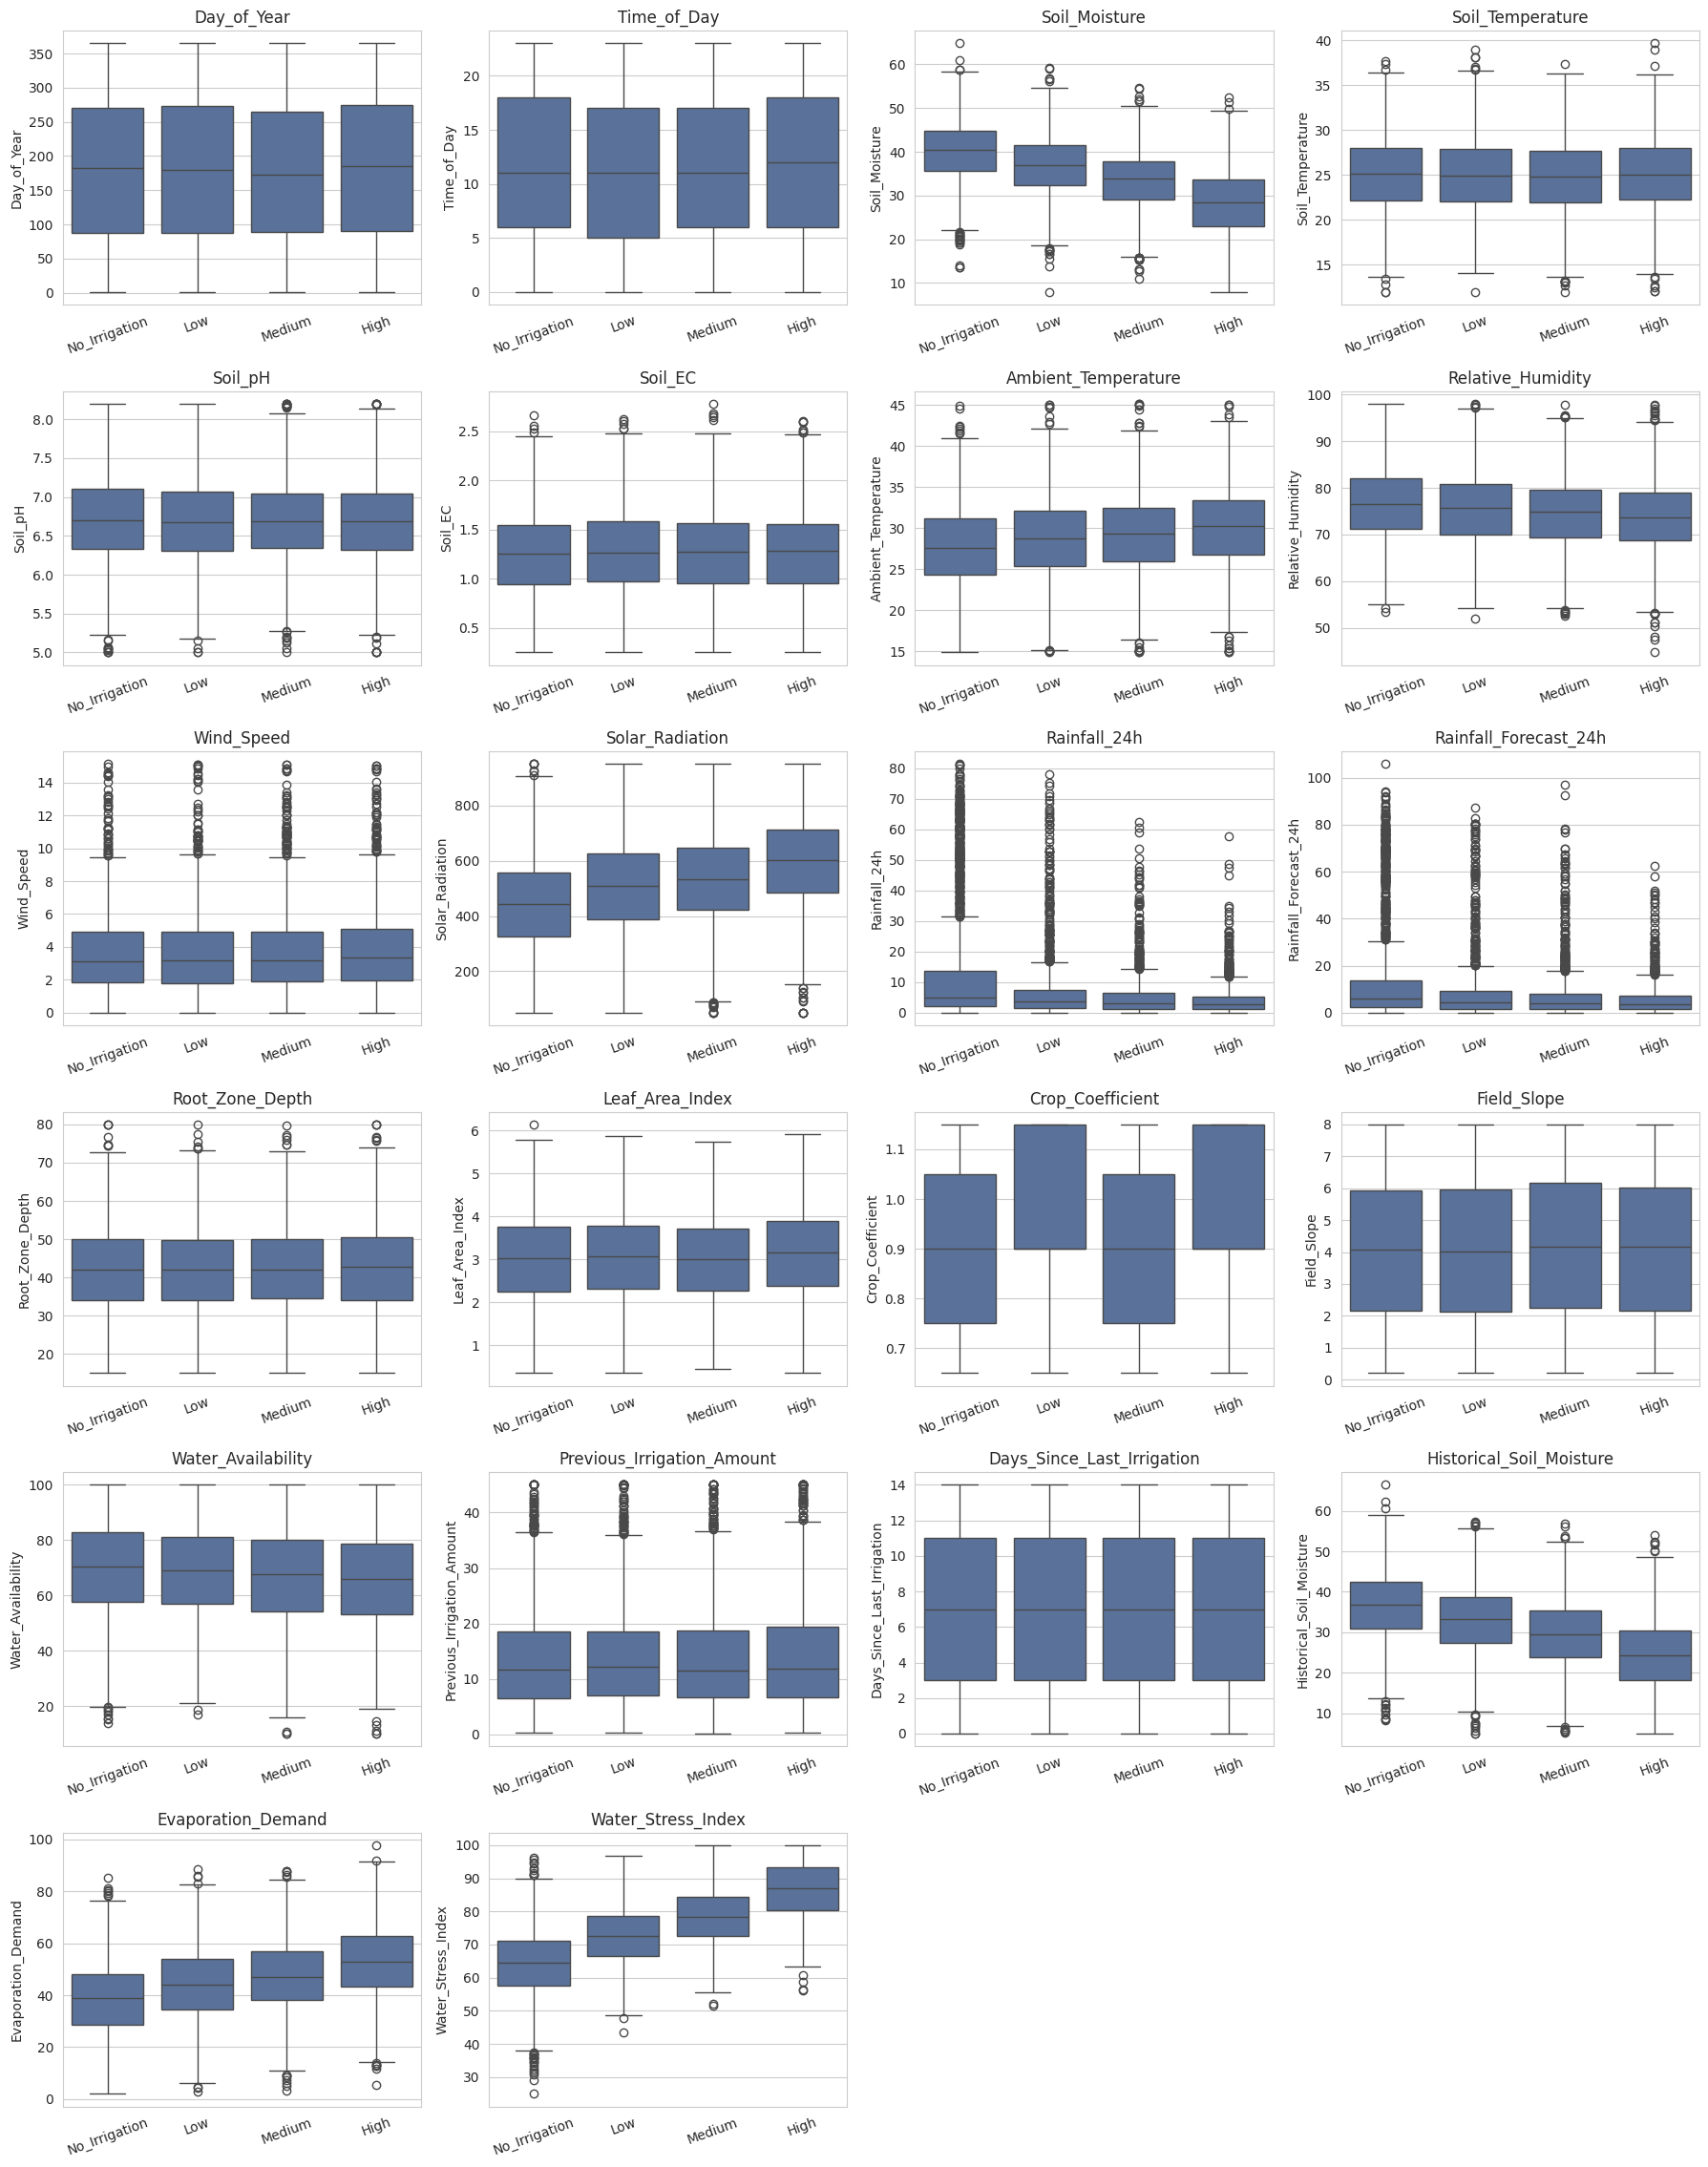

In [170]:
n_plot_cols = 4
n_plot_rows = int(np.ceil(len(numeric_features) / n_plot_cols))
fig, axes = plt.subplots(n_plot_rows, n_plot_cols, figsize=(18, 3.8 * n_plot_rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, ax=ax, color="#4F6EA4")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Conclusion:**
- The strong features change **steadily** from `No_Irrigation` to `High`.
  Soil moisture falls from +0.65 to -0.76 standard deviations, while solar
  radiation rises from -0.42 to +0.43. Rainfall is highest for
  `No_Irrigation`. The labels follow the physics in the expected direction,
  which is a useful sanity check on the data.
- The box plots overlap heavily, especially between **neighbouring** classes
  (`Low` against `Medium`). The classes are not cleanly separable.

**What this means for the model:** expect most mistakes to fall between
neighbouring classes (predicting `Low` when the answer is `Medium`), and few
between the extremes (`No_Irrigation` against `High`). This also explains why
the earlier draft's models scored only about 0.51 macro-F1. Section 9 checks
whether the errors really fall between neighbours, which matters for the
farmer: a near miss is far less harmful than recommending heavy irrigation
when none is needed.

### 3.6 Correlation between numeric features

**Why:** two features that are strongly correlated carry largely the same
information. This matters for three reasons:
- logistic regression coefficients become unstable and harder to interpret;
- feature importance is split between the two features, so each looks weaker
  than it is;
- when one of a pair is dropped, the other can stand in for it, so dropping is
  cheap.

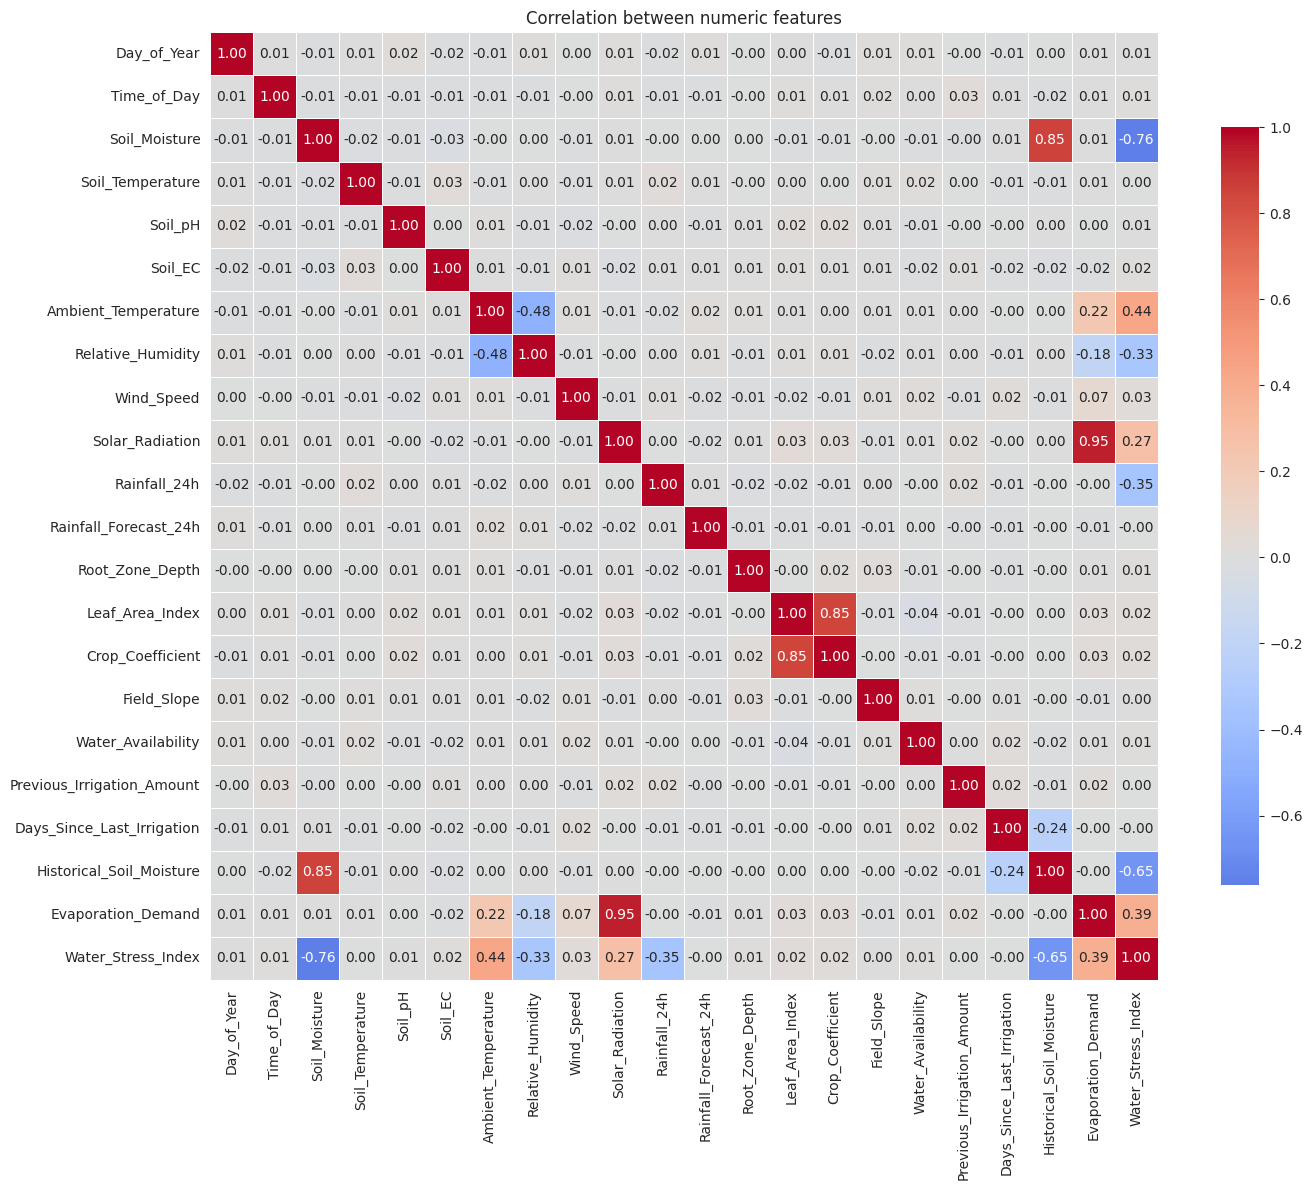

In [171]:
plt.figure(figsize=(15, 12))
sns.heatmap(df[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

**Conclusion:** most features are uncorrelated (|r| < 0.05), as you would
expect from synthetic data. The notable pairs are:

| Pair | r | Meaning |
|---|---|---|
| `Solar_Radiation` – `Evaporation_Demand` | 0.95 | almost the same information |
| `Soil_Moisture` – `Historical_Soil_Moisture` | 0.85 | today's moisture tracks the recent average |
| `Leaf_Area_Index` – `Crop_Coefficient` | 0.85 | both describe crop size and stage |
| `Ambient_Temperature` – `Relative_Humidity` | -0.48 | hot air tends to be drier |
| `Water_Stress_Index` – `Soil_Moisture` | -0.76 | |
| `Water_Stress_Index` – `Historical_Soil_Moisture` | -0.65 | |
| `Water_Stress_Index` – `Ambient_Temperature` | 0.44 | |

**Decisions:**
- **Dropping `Evaporation_Demand` (section 2.2) should cost little.**
  `Solar_Radiation` carries almost the same information (r = 0.95). Section 5
  measures this.
- **Dropping `Water_Stress_Index` is less costly than its rank suggests.** It
  is largely a combination of soil moisture, temperature and rainfall, which
  the app *does* send, so the model can partly rebuild it.
- The other correlated pairs are kept for now. Section 5 tests whether one of
  each pair is redundant.

### 3.7 EDA summary

| Finding | Used in |
|---|---|
| Classes perfectly balanced, so no resampling, macro-F1 as the metric, and a 25% baseline | sections 4, 7 |
| Rainfall strongly skewed, so a Yeo-Johnson transform | section 6 |
| Scales differ widely, so standardise for linear and distance-based models | section 6 |
| Outliers are real extremes, so no rows are removed | section 6 |
| Strongest signals: soil moisture (today and recent), sun, rain, soil type | section 5 |
| Weak on every test: slope, root depth, previous irrigation, pH, EC, time, day, wind, soil temperature | section 5 |
| `Evaporation_Demand` ≈ `Solar_Radiation`, and `Water_Stress_Index` is largely rebuilt from sent features | section 5 |
| Neighbouring classes overlap, so expect near-miss errors | sections 7, 9 |

## 4. Train/test split

**Why split at all:** a model always looks good on the data it learned from.
To know how it will do on a farm it has never seen, part of the data is held
back as a **test set** and used exactly **once**, in section 9, to score the
final model.

**Decisions:**

| Choice | Reason |
|---|---|
| **80% train / 20% test** | 7,000 rows give 1,400 test rows, or 350 per class. That is enough for stable per-class scores: the standard error of an accuracy score is about 1.3 percentage points. |
| **Stratified by `Irrigation_Action`** | Both sets keep the 25% balance from section 3.1, so the test score is not distorted by an unlucky mix of classes. |
| **`random_state = RANDOM_STATE`** | The same rows land in the test set on every run, so results are reproducible. |
| **Split before feature selection** | Feature selection (section 5) uses only the training set. If it looked at the test set, the test set would have influenced the model, and its score would be too optimistic. |
| **No separate validation set** | Model comparison and tuning (sections 7–8) use cross-validation on the training set. Every training row then serves for both training and validation, which uses 7,000 rows more efficiently than a fixed validation slice. |

All 25 candidate features are kept at this point, including
`Water_Stress_Index` and `Evaporation_Demand`. Section 5 needs them to
*measure* what dropping them costs. The final feature list is decided there.

In [172]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

candidate_features = [col for col in df.columns if col not in (ID_COL, TARGET)]

X = df[candidate_features]
y = df[TARGET]

print(f"{len(candidate_features)} candidate features, {len(X)} rows")

25 candidate features, 7000 rows


### 4.1 Does the same field appear in both sets?

`Field_ID` repeats: 7,000 rows come from far fewer fields, so each field has
many readings. This raises a question that matters for an honest test score.

- If a field's readings are **consistent** (for example, the same soil type
  every time), they behave like one real field. A random split would then put
  readings from the same field in both sets. The model could recognise the
  field instead of learning the general pattern, and the test score would be
  too optimistic. In that case, all readings from one field must go to the
  same side of the split (a **group split**).
- If a field's readings are **not consistent**, `Field_ID` is only a label the
  data generator assigned at random, and a normal stratified split is
  correct.

The app predicts for farmers' fields that were never in the dataset, so the
test must imitate that. The check below decides which split to use.

In [173]:
rows_per_field = df.groupby(ID_COL).size()
soil_types_per_field = df.groupby(ID_COL)["Soil_Type"].nunique()
share_consistent = (soil_types_per_field == 1).mean()

print(f"Fields: {len(rows_per_field)}, rows per field: {rows_per_field.min()} to {rows_per_field.max()}")
print(f"Fields with a single soil type across all their rows: {share_consistent:.0%}")

USE_GROUP_SPLIT = share_consistent >= 0.95
print(f"Group split by {ID_COL}: {USE_GROUP_SPLIT}")

Fields: 100, rows per field: 48 to 89
Fields with a single soil type across all their rows: 0%
Group split by Field_ID: False


**Result:** 100 fields with 48–89 rows each, and **0%** of them keep the same
soil type across their rows. `Field_ID` is therefore a label the data
generator assigned at random, not a real field, so a **stratified random
split** is correct (`USE_GROUP_SPLIT = False`). All 100 field IDs appearing in
both sets (4.3) is expected and harmless.

**How to read it:** with four soil types assigned at random, a field with
dozens of rows (see the printout above) would almost never show the same
soil type every time. So:

- **close to 100% consistent** → fields are real entities → group split;
- **close to 0% consistent** → `Field_ID` is a random label → stratified
  random split.

`USE_GROUP_SPLIT` records the outcome. Sections 7–8 use it to pick the
matching cross-validation (`StratifiedGroupKFold` or `StratifiedKFold`).

### 4.2 Split

Both options give an 80/20 split stratified by class.

- **Random split:** `train_test_split` with `stratify=y`.
- **Group split:** `StratifiedGroupKFold` with 5 folds, where one fold
  (20% of the fields) becomes the test set. It keeps every field on one side
  while keeping the classes as balanced as the groups allow.

In [174]:
if USE_GROUP_SPLIT:
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    train_idx, test_idx = next(splitter.split(X, y, groups=df[ID_COL]))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )

groups_train = df.loc[X_train.index, ID_COL]  # used by group cross-validation, if enabled

print(f"Training set: {len(X_train)} rows")
print(f"Test set:     {len(X_test)} rows")

Training set: 5600 rows
Test set:     1400 rows


### 4.3 Checks

Two checks confirm the split did what we intended:
1. **Class balance** is the same in both sets as in the full data.
2. **No leakage:** no row appears in both sets and, for a group split, no
   field appears in both.

In [175]:
balance_check = pd.DataFrame({
    "full data": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).loc[CLASS_ORDER].round(3)

balance_check

,full data,train,test
Irrigation_Action,,,
No_Irrigation,0.25,0.25,0.25
Low,0.25,0.25,0.25
Medium,0.25,0.25,0.25
High,0.25,0.25,0.25


In [176]:
assert X_train.index.intersection(X_test.index).empty, "A row is in both sets"

shared_fields = set(df.loc[X_train.index, ID_COL]) & set(df.loc[X_test.index, ID_COL])
print(f"Fields appearing in both sets: {len(shared_fields)}")
if USE_GROUP_SPLIT:
    assert not shared_fields, "Group split leaked a field into both sets"

print("Split checks passed.")

Fields appearing in both sets: 100
Split checks passed.


**Conclusion:** the training set (about 5,600 rows) is used for everything in
sections 5–8. The test set (about 1,400 rows) is **not touched again until
section 9.**

If the split is random, many fields appear in both sets. That is expected,
and harmless, because the check in 4.1 showed `Field_ID` is not a real field
identity. If the split is a group split, the count must be 0.

## 5. Feature selection

**Goal:** decide the final list of features, `FEATURES`, that the model is
trained on and that the API expects.

Three kinds of evidence are combined, from weakest to strongest:

1. **Constraint:** the model can only use features the app can actually
   send (section 2.2).
2. **Filter statistics** on the training set: ANOVA and mutual information.
   They are quick, but they judge each feature on its own.
3. **Ablation experiments:** train the same model with and without a feature
   (or a group of features) and compare cross-validated scores. This directly
   measures what a feature contributes *alongside the others*, which is the
   question that actually matters.

Everything in this section uses the **training set only**.

### 5.1 Constraint: what the app can send

Two candidates can never be supplied by the app:

- `Water_Stress_Index`: the app has no way to measure it (no canopy
  temperature sensor) and no documented formula for it.
- `Evaporation_Demand`: its unit is undocumented, so no conversion from ET₀
  can be trusted (section 2.2).

They are removed from the *app-supplied* list. They stay in `X_train` for now,
because 5.4 and 5.5 use them to measure what their absence costs.

In [177]:
NOT_SENT_BY_APP = ["Water_Stress_Index", "Evaporation_Demand"]

APP_FEATURES = [f for f in candidate_features if f not in NOT_SENT_BY_APP]
app_numeric = [f for f in APP_FEATURES if f not in categorical_features]

print(f"{len(APP_FEATURES)} features the app can send:")
print(APP_FEATURES)

23 features the app can send:
['Crop_Type', 'Growth_Stage', 'Soil_Type', 'Day_of_Year', 'Time_of_Day', 'Soil_Moisture', 'Soil_Temperature', 'Soil_pH', 'Soil_EC', 'Ambient_Temperature', 'Relative_Humidity', 'Wind_Speed', 'Solar_Radiation', 'Rainfall_24h', 'Rainfall_Forecast_24h', 'Root_Zone_Depth', 'Leaf_Area_Index', 'Crop_Coefficient', 'Field_Slope', 'Water_Availability', 'Previous_Irrigation_Amount', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture']


### 5.2 Filter statistics on the training set

Section 3 computed these on the full dataset to *describe* the data. Here
they are recomputed on the **training set only**, so any decision that leans
on them is free of test-set influence. The ranking should closely match
section 3. A large difference would suggest an unlucky split.

In [178]:
train_numeric_filled = X_train[app_numeric].fillna(X_train[app_numeric].median())
f_train, p_train = f_classif(train_numeric_filled, y_train)

mi_train_input = train_numeric_filled.copy()
for col in categorical_features:
    mi_train_input[col] = X_train[col].astype("category").cat.codes

mi_train = mutual_info_classif(
    mi_train_input, y_train,
    discrete_features=[col in categorical_features for col in mi_train_input.columns],
    random_state=RANDOM_STATE,
)

In [179]:
filter_summary = pd.DataFrame({"mutual_info": mi_train}, index=mi_train_input.columns)
filter_summary["ANOVA_F"] = pd.Series(f_train, index=app_numeric)
filter_summary["ANOVA_p"] = pd.Series(p_train, index=app_numeric)

filter_summary.sort_values("mutual_info", ascending=False).round(4)

,mutual_info,ANOVA_F,ANOVA_p
Soil_Moisture,0.1444,691.8801,0.0000
Historical_Soil_Moisture,0.1385,497.4053,0.0000
Soil_Type,0.0728,NaN,NaN
Solar_Radiation,0.0416,195.8217,0.0000
Rainfall_24h,0.0376,201.3156,0.0000
Rainfall_Forecast_24h,0.0229,103.0036,0.0000
Field_Slope,0.0156,0.8561,0.4632
Relative_Humidity,0.0131,35.6166,0.0000
Time_of_Day,0.0067,0.2090,0.8903
Ambient_Temperature,0.0061,54.6137,0.0000


**Reading it:** ANOVA is blank for the three categorical features, because it
only applies to numeric ones; mutual information covers all of them. Features
near the bottom on *both* measures are the drop candidates tested in 5.6. A
feature is never dropped on these numbers alone, because they ignore how
features work together.

### 5.3 The measuring tool: one fixed model, cross-validated

Each ablation trains the **same** model on a different feature list and
reports the cross-validated **macro-F1** (section 3.1). Only the feature list
changes, so any difference in score is caused by the features.

**Why a Random Forest as the measuring tool:**
- it captures non-linear effects and interactions, so it does not undervalue
  a feature the way a linear model can;
- it needs no scaling or transforms, so the comparison does not depend on
  preprocessing choices made later in section 6;
- it is robust and quick to train.

The model compared in sections 7–8 may be a different algorithm. Section 7
re-checks the chosen features with all of them.

**Cross-validation:** 5 folds on the training set. If section 4.1 found that
fields are real, the folds keep each field together (`StratifiedGroupKFold`);
otherwise a normal `StratifiedKFold` is used.

In [180]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

if USE_GROUP_SPLIT:
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_groups = groups_train
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_groups = None

In [181]:
def make_yardstick_pipeline(numeric_cols, categorical_cols, extra_steps=()):
    """Minimal preprocessing + a fixed Random Forest, used only to compare feature sets."""
    preprocess = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_cols),
    ])
    model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
    return Pipeline([*extra_steps, ("preprocess", preprocess), ("model", model)])

In [182]:
ablation_results = {}


def run_experiment(name, features, extra_steps=(), extra_numeric=(), extra_columns=()):
    """Cross-validate the yardstick model on a feature list and record macro-F1."""
    numeric_cols = [f for f in features if f not in categorical_features] + list(extra_numeric)
    categorical_cols = [f for f in features if f in categorical_features]
    pipeline = make_yardstick_pipeline(numeric_cols, categorical_cols, extra_steps)

    scores = cross_val_score(
        pipeline, X_train[list(features) + list(extra_columns)], y_train,
        cv=cv, groups=cv_groups, scoring="f1_macro", n_jobs=-1,
    )
    ablation_results[name] = {"features": len(features), "macro_f1": scores.mean(), "std": scores.std()}
    print(f"{name:45s} macro-F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")
    return scores.mean()

### 5.4 What do `Evaporation_Demand` and `Water_Stress_Index` cost?

Four experiments isolate each feature's contribution:

| Experiment | Purpose |
|---|---|
| All 25 candidates | The **ceiling**: the best this model can do with every column, including the two the app cannot send. Not achievable in production. |
| Without `Evaporation_Demand` | The cost of the section 2.2 decision |
| Without `Water_Stress_Index` | The cost of not having the index |
| App features only (both removed) | What production actually gets |

In [183]:
score_ceiling = run_experiment("All 25 candidates (ceiling)", candidate_features)
score_no_evap = run_experiment("Without Evaporation_Demand",
                               [f for f in candidate_features if f != "Evaporation_Demand"])
score_no_wsi = run_experiment("Without Water_Stress_Index",
                              [f for f in candidate_features if f != "Water_Stress_Index"])
score_app = run_experiment("App features only", APP_FEATURES)

All 25 candidates (ceiling)                   macro-F1 = 0.5166 (+/- 0.0111)
Without Evaporation_Demand                    macro-F1 = 0.5102 (+/- 0.0092)
Without Water_Stress_Index                    macro-F1 = 0.5069 (+/- 0.0102)
App features only                             macro-F1 = 0.5042 (+/- 0.0122)


**How to read it:**
- *Ceiling minus "Without Evaporation_Demand"* is what dropping
  `Evaporation_Demand` costs. Section 3.6 predicts that this is small,
  because `Solar_Radiation` carries the same information (r = 0.95).
- *Ceiling minus "Without Water_Stress_Index"* is what the index is worth.
- *Ceiling minus "App features only"* is the total price of the app's
  constraints. 5.5 tries to win part of it back.

Record these numbers in the thesis: they turn "we dropped two features" into
a measured, defensible decision.

### 5.5 Can `Water_Stress_Index` be rebuilt?

The index is undocumented, but its range (24.9–100, most often exactly 100)
and its correlations (section 3.6) suggest the data generator *calculated* it
from other columns and capped it at 100. If so, it can be estimated from the
features the app does send.

**Step 1: how much of it can be predicted?** We fit two regressions from the
app's numeric features to the index and report cross-validated **R²** (the
share of its variation they explain: 1 = perfectly, 0 = not at all):

- **Linear regression:** a high R² here means the index is roughly a
  weighted sum of the inputs, which is a simple formula.
- **Gradient boosting:** captures non-linear formulas and the cap at 100.

In [184]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

wsi_target = X_train["Water_Stress_Index"]
regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

linear_wsi = Pipeline([("impute", SimpleImputer(strategy="median")), ("model", LinearRegression())])
boosted_wsi = HistGradientBoostingRegressor(random_state=RANDOM_STATE)  # handles missing values itself

r2_linear = cross_val_score(linear_wsi, X_train[app_numeric], wsi_target, cv=regression_cv, scoring="r2")
r2_boosted = cross_val_score(boosted_wsi, X_train[app_numeric], wsi_target, cv=regression_cv, scoring="r2")

print(f"R² linear regression:  {r2_linear.mean():.3f} (+/- {r2_linear.std():.3f})")
print(f"R² gradient boosting:  {r2_boosted.mean():.3f} (+/- {r2_boosted.std():.3f})")

R² linear regression:  0.986 (+/- 0.001)
R² gradient boosting:  0.981 (+/- 0.001)


**How to read it:**

| R² | Meaning |
|---|---|
| about 1.0 | The index is a formula of features we already have; nothing is really lost. |
| 0.7 – 0.95 | Mostly rebuildable; an estimate should recover much of its value. |
| below 0.5 | Mostly hidden information; an estimate will add little. |

**Step 2: build the estimate into the pipeline.** The estimate is computed by
a pipeline step, `WaterStressEstimator`, so the app never sends the index. It
is calculated the same way in training and in production.

Two details make it trustworthy:
- It is **fitted on training folds only**, like every other step, so nothing
  leaks from validation or test data.
- During training, each row gets an **out-of-fold** estimate: a value
  predicted by a regressor that did not see that row. Production estimates
  are never perfect, so the classifier must learn from estimates that are
  equally imperfect, not from memorised near-perfect ones.

In [185]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_val_predict


class WaterStressEstimator(BaseEstimator, TransformerMixin):
    """Adds an estimate of Water_Stress_Index, computed from features the app sends."""

    def __init__(self, input_cols, target_col="Water_Stress_Index",
                 output_col="Water_Stress_Index_est", random_state=None):
        self.input_cols = input_cols
        self.target_col = target_col
        self.output_col = output_col
        self.random_state = random_state

    def _new_regressor(self):
        return HistGradientBoostingRegressor(random_state=self.random_state)

    def fit(self, X, y=None):
        self.regressor_ = self._new_regressor().fit(X[self.input_cols], X[self.target_col])
        return self

    def transform(self, X):
        """Production path: estimate the index; drop the true one if present."""
        X_out = X.drop(columns=[self.target_col], errors="ignore").copy()
        X_out[self.output_col] = self.regressor_.predict(X_out[self.input_cols])
        return X_out

    def fit_transform(self, X, y=None):
        """Training path: out-of-fold estimates, so training rows are as noisy as production."""
        folds = KFold(n_splits=5, shuffle=True, random_state=self.random_state)
        out_of_fold = cross_val_predict(self._new_regressor(), X[self.input_cols], X[self.target_col], cv=folds)
        self.fit(X)
        X_out = X.drop(columns=[self.target_col]).copy()
        X_out[self.output_col] = out_of_fold
        return X_out

In section 11 this class moves into a small Python file that both this notebook and the
FastAPI service import. A saved pipeline can only be loaded where its custom
classes can be imported under the same name.

**Step 3: does the estimate help?** The same experiment as "App features
only", plus the estimated index. The true index is passed in only so the
estimator can learn from it. The estimator removes it before the classifier
sees anything.

In [186]:
wsi_step = ("estimate_wsi", WaterStressEstimator(input_cols=app_numeric, random_state=RANDOM_STATE))

score_app_wsi = run_experiment(
    "App features + estimated Water_Stress_Index", APP_FEATURES,
    extra_steps=[wsi_step],
    extra_numeric=["Water_Stress_Index_est"],
    extra_columns=["Water_Stress_Index"],
)

recovered = (score_app_wsi - score_app) / max(score_ceiling - score_app, 1e-9)
print(f"\nShare of the gap to the ceiling recovered by the estimate: {recovered:.0%}")

App features + estimated Water_Stress_Index   macro-F1 = 0.5085 (+/- 0.0086)

Share of the gap to the ceiling recovered by the estimate: 35%


**Result: `Water_Stress_Index` is a formula of features the app already sends.**

- **R² = 0.986 (linear) and 0.981 (gradient boosting).** The app's features
  explain about 99% of the index's variation, and a simple weighted sum is
  enough to do it. The data generator calculated the index from those columns.
- **This explains why it ranked as the strongest feature in section 3:** it
  *summarises* several strong features (soil moisture, temperature, rainfall)
  in one number. But that information is already in the inputs, which is why
  removing the index costs only about 1 point of macro-F1 (5.4).
- **Adding the estimate gains only 0.0043** (35% of a small gap). That is below
  the 0.01 tolerance and within cross-validation noise, so the estimate is
  **not used.** It would add a custom pipeline component (and a `.py` file the
  API must import) for no measurable benefit.

**Thesis wording:** *Water_Stress_Index could not be measured by the system,
but it was shown to be reconstructible (R² = 0.99) from features the system
does collect, so excluding it loses negligible information (−0.010 macro-F1).*

**Decision rule:** the estimate is kept if it improves macro-F1 over "App
features only" by more than `TOLERANCE` (defined below). A smaller gain is
within the noise of cross-validation and does not justify the extra component.

### 5.6 Do the weak features earn their place?

Two groups looked weak in section 3:

| Group | Features | Evidence |
|---|---|---|
| **Weak signals** | `Field_Slope`, `Root_Zone_Depth`, `Previous_Irrigation_Amount`, `Soil_pH`, `Soil_EC`, `Time_of_Day`, `Day_of_Year`, `Wind_Speed`, `Soil_Temperature` | ANOVA p > 0.05 and MI ≈ 0 |
| **Crop descriptors** | `Crop_Type`, `Growth_Stage`, `Crop_Coefficient`, `Leaf_Area_Index` | Cramér's V ≈ 0.01–0.03, weak ANOVA |

Each group is removed as a whole and the score compared. Groups are tested
rather than single features because weak features can matter together even
when none matters alone.

**Decision rule:** a group is dropped if removing it lowers macro-F1 by no
more than `TOLERANCE`. The tolerance is set at 0.01, which is about the
typical fold-to-fold variation seen above. A smaller change cannot be told
apart from noise.

**Why prefer fewer features when scores tie:** every feature the model uses
is a value the app must supply correctly, in the right unit. Dropping
`Root_Zone_Depth` and `Previous_Irrigation_Amount`, for example, also removes
two of the unit conversions from section 2.2, which means less to build and
less that can go wrong.

A note on the crop descriptors: agronomy says crop and growth stage matter
for water need. If the data says otherwise, that is a property of this
synthetic dataset, and it is reported as a limitation, not hidden.

In [187]:
TOLERANCE = 0.01

USE_WSI_ESTIMATE = score_app_wsi > score_app + TOLERANCE

WEAK_SIGNALS = ["Field_Slope", "Root_Zone_Depth", "Previous_Irrigation_Amount", "Soil_pH", "Soil_EC",
                "Time_of_Day", "Day_of_Year", "Wind_Speed", "Soil_Temperature"]
CROP_DESCRIPTORS = ["Crop_Type", "Growth_Stage", "Crop_Coefficient", "Leaf_Area_Index"]

print(f"Use the estimated Water_Stress_Index: {USE_WSI_ESTIMATE}")

Use the estimated Water_Stress_Index: False


In [188]:
if USE_WSI_ESTIMATE:
    wsi_kwargs = dict(extra_steps=[wsi_step], extra_numeric=["Water_Stress_Index_est"],
                      extra_columns=["Water_Stress_Index"])
    score_base = score_app_wsi
else:
    wsi_kwargs = {}
    score_base = score_app


def without(features, group):
    return [f for f in features if f not in group]


score_no_weak = run_experiment("Base without weak signals", without(APP_FEATURES, WEAK_SIGNALS), **wsi_kwargs)
score_no_crop = run_experiment("Base without crop descriptors", without(APP_FEATURES, CROP_DESCRIPTORS), **wsi_kwargs)
score_no_both = run_experiment("Base without both groups",
                               without(APP_FEATURES, WEAK_SIGNALS + CROP_DESCRIPTORS), **wsi_kwargs)

Base without weak signals                     macro-F1 = 0.5000 (+/- 0.0082)
Base without crop descriptors                 macro-F1 = 0.5069 (+/- 0.0061)
Base without both groups                      macro-F1 = 0.5029 (+/- 0.0125)


In [189]:
DROP_WEAK = score_no_weak >= score_base - TOLERANCE
DROP_CROP = score_no_crop >= score_base - TOLERANCE

# Both groups were also tested together, so a joint drop must hold up on its own
if DROP_WEAK and DROP_CROP and score_no_both < score_base - TOLERANCE:
    DROP_CROP = False  # keep the smaller drop; the crop group is the one with domain backing

print(f"Base score: {score_base:.4f}")
print(f"Drop weak signals:    {DROP_WEAK}")
print(f"Drop crop descriptors: {DROP_CROP}")

Base score: 0.5042
Drop weak signals:    True
Drop crop descriptors: True


### 5.7 Final feature list

`FEATURES` is assembled from the decisions above. It is the single list used
from here on: by the preprocessing pipeline (section 6), by every model
(sections 7–9) and in the saved model's metadata for the API (section 11).

In [190]:
FEATURES = list(APP_FEATURES)
if DROP_WEAK:
    FEATURES = without(FEATURES, WEAK_SIGNALS)
if DROP_CROP:
    FEATURES = without(FEATURES, CROP_DESCRIPTORS)

print(f"{len(FEATURES)} final features: {FEATURES}")
print(f"Plus estimated Water_Stress_Index inside the pipeline: {USE_WSI_ESTIMATE}")

10 final features: ['Soil_Type', 'Soil_Moisture', 'Ambient_Temperature', 'Relative_Humidity', 'Solar_Radiation', 'Rainfall_24h', 'Rainfall_Forecast_24h', 'Water_Availability', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture']
Plus estimated Water_Stress_Index inside the pipeline: False


In [191]:
ablation_summary = pd.DataFrame(ablation_results).T
ablation_summary["gap_to_ceiling"] = ablation_summary["macro_f1"] - score_ceiling
ablation_summary.astype({"features": int}).round(4)

,features,macro_f1,std,gap_to_ceiling
All 25 candidates (ceiling),25,0.5166,0.0111,0.0000
Without Evaporation_Demand,24,0.5102,0.0092,-0.0065
Without Water_Stress_Index,24,0.5069,0.0102,-0.0098
App features only,23,0.5042,0.0122,-0.0124
App features + estimated Water_Stress_Index,23,0.5085,0.0086,-0.0081
Base without weak signals,14,0.5000,0.0082,-0.0167
Base without crop descriptors,19,0.5069,0.0061,-0.0097
Base without both groups,10,0.5029,0.0125,-0.0137


**Results**

| Decision | Change in macro-F1 | Verdict |
|---|---|---|
| Drop `Evaporation_Demand` | −0.0065 vs ceiling | Within noise (one standard deviation ≈ 0.01). Confirms section 3.6: `Solar_Radiation` carries the same information. |
| Drop `Water_Stress_Index` | −0.0098 vs ceiling | About one standard deviation; the index can be rebuilt (R² 0.99). |
| Everything the app cannot send | −0.0124 vs ceiling | The full price of the app's constraints: about 1 point. |
| Drop the 9 weak signals | −0.0042 vs base | Within tolerance, so **dropped**. |
| Drop the 4 crop descriptors | +0.0027 vs base | No loss, so **dropped**. |
| Drop both groups | −0.0013 vs base | **Final: 10 features**, within 1.4 points of the ceiling. |

**The most important finding: the ceiling is 0.52.** Even with every column,
including the two the app cannot send, the model reaches only about 52%
macro-F1 (chance is 25%). The limit therefore comes from the **dataset**, not
from our feature choices. Its labels contain variation that no feature
explains, which matches the heavy overlap between neighbouring classes seen
in section 3.5. The final model gets within 1.4 points of that ceiling using
fewer than half of the features.

**What this means for the next sections:**
- Sections 7–8 test whether other algorithms or tuning can beat about 0.50.
  Expectations should be modest, because the yardstick already sits close to
  the ceiling.
- Section 9 checks whether the errors are **near misses** (`Low` against
  `Medium`) or serious ones (`No_Irrigation` against `High`). That decides
  how useful 52% is to a farmer.

**Effect on the app:** the model now needs only 10 inputs. The API ignores
extra keys, so the app keeps working unchanged. The unit conversions for
`Root_Zone_Depth` and `Previous_Irrigation_Amount` from section 2.2 are no
longer needed. `Solar_Radiation`, `Water_Availability` and the
`Days_Since_Last_Irrigation` clip still are.

**Summary of section 5:**
- The model uses only features the app can send. The price of that constraint
  is measured against the ceiling in the table above.
- `Water_Stress_Index` is either rebuilt inside the pipeline or left out, as
  decided by measurement (5.5). The app never sends it either way.
- Weak feature groups are dropped only where the score shows they add nothing.
  This also simplifies the app's work.
- All decisions use the training set. The test set is still untouched.

**Thesis note:** the ablation table is the evidence for the feature-selection
chapter. Each row is one decision, with its measured effect.

## 6. Preprocessing pipeline

Raw features cannot go straight into most models. Missing values must be
filled in, text categories turned into numbers, and skewed or differently
scaled features brought onto a common footing. All of these steps are bundled
into one scikit-learn **pipeline**.

**Why a pipeline rather than transforming the data by hand:**
- **The same steps run in training and in production.** The FastAPI service
  loads one file containing both the preprocessing and the model, so an app
  payload is transformed exactly as the training data was.
- **No leakage during cross-validation.** Medians, scaling parameters and
  category lists are learned inside each training fold only, never from the
  validation fold.
- **One object to save** in section 11.

The pipeline is built from `FEATURES` (section 5), so it adapts if that list
changes.

### 6.1 Column groups

Each feature gets the treatment its type and distribution need (section 3):

| Group | Treatment | Applies to |
|---|---|---|
| **Numeric** | median imputation, then standardisation | roughly symmetric numeric features |
| **Skewed** | median imputation, then Yeo-Johnson transform | rainfall (skewness about 3.4, section 3.2), plus wind and previous irrigation if they are ever selected |
| **Nominal** | most-frequent imputation, then one-hot encoding | categories with no natural order (`Soil_Type`, `Crop_Type`) |
| **Ordinal** | most-frequent imputation, ordinal encoding, then standardisation | categories with a natural order (`Growth_Stage`: seedling to maturity) |

Groups are defined from candidate lists and then filtered by `FEATURES`, so a
feature dropped in section 5 simply disappears from its group.

In [192]:
NOMINAL_CANDIDATES = ["Crop_Type", "Soil_Type"]
ORDINAL_ORDERS = {"Growth_Stage": ["Seedling", "Vegetative", "Flowering", "Fruiting", "Maturity"]}
SKEWED_CANDIDATES = ["Rainfall_24h", "Rainfall_Forecast_24h", "Wind_Speed", "Previous_Irrigation_Amount"]

nominal_cols = [f for f in FEATURES if f in NOMINAL_CANDIDATES]
ordinal_cols = [f for f in FEATURES if f in ORDINAL_ORDERS]
skewed_cols = [f for f in FEATURES if f in SKEWED_CANDIDATES]
numeric_cols = [f for f in FEATURES if f not in nominal_cols + ordinal_cols + skewed_cols]

for name, group in [("numeric", numeric_cols), ("skewed", skewed_cols),
                    ("nominal", nominal_cols), ("ordinal", ordinal_cols)]:
    print(f"{name:8s} ({len(group)}): {group}")

numeric  (7): ['Soil_Moisture', 'Ambient_Temperature', 'Relative_Humidity', 'Solar_Radiation', 'Water_Availability', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture']
skewed   (2): ['Rainfall_24h', 'Rainfall_Forecast_24h']
nominal  (1): ['Soil_Type']
ordinal  (0): []


**Guards:** these checks stop the notebook here if a feature was forgotten,
assigned twice, or put in the wrong kind of group. A mistake like that would
otherwise go unnoticed: the earlier draft silently dropped both rainfall
features this way.

In [193]:
from pandas.api.types import is_numeric_dtype

assigned = nominal_cols + ordinal_cols + skewed_cols + numeric_cols
assert sorted(assigned) == sorted(FEATURES), f"Mismatch: {set(assigned) ^ set(FEATURES)}"

for col in skewed_cols + numeric_cols:
    assert is_numeric_dtype(X_train[col]), f"{col} is text but sits in a numeric group"

for col in ordinal_cols:
    unexpected = set(X_train[col].dropna()) - set(ORDINAL_ORDERS[col])
    assert not unexpected, f"{col} has labels missing from its order: {unexpected}"

print("Column groups are complete and consistent.")

Column groups are complete and consistent.


### 6.2 Missing values: median imputation

In training, missing values are rare (0.5% of six columns) and occur at
random. In production they mean something specific: the weather API failed,
a farmer's first submission has no history yet, or a field has never been
irrigated.

**Decision: fill with the training median, and add no "was missing" flag.**
- The median is a neutral value: it does not push the prediction towards any
  class, and unlike the mean it is not dragged by skewed tails such as
  rainfall.
- A missing-value flag would have to *learn* what missing means from the
  training data. Training gaps are random and rare, so it would learn nothing
  useful there, while carrying a different meaning in production.

**Note for the app:** for `Days_Since_Last_Irrigation`, a field that has never
been irrigated is better sent as **14** ("14 days or more") than omitted.
Omitting it would impute the median of 7 days, which wrongly tells the model
the field was watered a week ago.

In [194]:
from sklearn.preprocessing import OrdinalEncoder, PowerTransformer, StandardScaler

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

**Why standardise** (rescale to mean 0, standard deviation 1): logistic
regression, KNN and SVM compare features by size. Without scaling,
`Solar_Radiation` (hundreds) would drown out `Relative_Humidity` (tens) for no
real reason. Tree models ignore scale, so the step is harmless for them, and
one shared pipeline keeps the model comparison in section 7 fair.

### 6.3 Skewed features: Yeo-Johnson transform

Rainfall has a long right tail: most days are dry or light, and a few have
heavy rain. A power transform compresses that tail so the distribution
becomes closer to symmetric, which helps linear and distance-based models.

**Why Yeo-Johnson instead of Box-Cox or a log:** rainfall contains zeros.
Box-Cox and `log` both require values above 0, while Yeo-Johnson handles 0
(and negative values) directly. With `standardize=True` it also rescales the
result to mean 0 and standard deviation 1, so no separate scaler is needed.

In [195]:
skewed_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=True)),
])

### 6.4 Categorical features: encoding

**Nominal features** (no natural order) are **one-hot encoded**: one 0/1
column per category, for example `Soil_Type_Sandy`. Coding them as 0, 1, 2, 3
would invent an order (`Clay < Loamy < Sandy`) that does not exist.

**Unknown labels raise an error** (`handle_unknown="error"`). The earlier draft
used `"ignore"`, which turned a misspelled label such as `"sandy"` into all
zeros. The model then predicted without knowing the soil type, and nothing
signalled the mistake. Now a wrong label fails loudly, so the API can reject
the request instead of returning a quietly wrong recommendation.

**Ordinal features** keep their natural order (`Seedling` = 0 ... `Maturity` =
4), then are standardised like the other numbers. This group only takes
effect if `Growth_Stage` is in `FEATURES`.

In [196]:
nominal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="error", sparse_output=False)),
])

ordinal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[ORDINAL_ORDERS[col] for col in ordinal_cols])),
    ("scale", StandardScaler()),
])

### 6.5 Combine into one preprocessor

A `ColumnTransformer` sends each group of columns to its own sub-pipeline and
joins the results side by side.

- **`remainder="drop"`:** any column not in `FEATURES` is discarded. The app
  can keep sending all its fields, and the extras are ignored.
- **Empty groups are skipped,** for example the ordinal group when
  `Growth_Stage` was not selected.
- **Pandas output** keeps readable column names (such as `Soil_Type_Sandy`),
  which section 10 needs to explain the model.
- **A function, not a single shared object.** Every call returns a *fresh*
  preprocessor with fresh copies (`clone`) of the sub-pipelines. The earlier
  draft shared one preprocessor object between several pipelines, so fitting
  one pipeline silently refitted the preprocessor inside the others.
- **An optional feature list.** By default it is built for `FEATURES`.
  Section 7.7 passes a longer list to re-test the features dropped in
  section 5; the same grouping rules from 6.1 are applied to it.

In [197]:
from sklearn.base import clone


def build_preprocessor(features=None):
    """Return a new, unfitted preprocessor for `features` (default: FEATURES)."""
    features = FEATURES if features is None else list(features)
    nominal = [f for f in features if f in NOMINAL_CANDIDATES]
    ordinal = [f for f in features if f in ORDINAL_ORDERS]
    skewed = [f for f in features if f in SKEWED_CANDIDATES]
    numeric = [f for f in features if f not in nominal + ordinal + skewed]

    ordinal_step = clone(ordinal_pipeline).set_params(
        encode__categories=[ORDINAL_ORDERS[col] for col in ordinal])
    groups = [
        ("numeric", clone(numeric_pipeline), numeric),
        ("skewed", clone(skewed_pipeline), skewed),
        ("nominal", clone(nominal_pipeline), nominal),
        ("ordinal", ordinal_step, ordinal),
    ]
    transformer = ColumnTransformer(
        [group for group in groups if group[2]],  # skip empty groups
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return transformer.set_output(transform="pandas")

`ColumnTransformer` clones its sub-pipelines when it is fitted, so the
module-level `numeric_pipeline` and the others are only templates. Each call
to `build_preprocessor()` gives a fully independent copy.

### 6.6 Preview

The preprocessor is fitted on the training set **only to inspect the
output**. This fitted copy is not used for modelling: sections 7–8 refit a
fresh one inside every cross-validation fold.

**What to expect:** numeric and skewed columns have a mean of about 0 and a
standard deviation of about 1; one-hot columns are 0/1; there are no missing
values.

In [198]:
preview_preprocessor = build_preprocessor().fit(X_train[FEATURES])
X_train_preview = preview_preprocessor.transform(X_train[FEATURES])

print(f"Shape after preprocessing: {X_train_preview.shape}")
print(f"Missing values after preprocessing: {int(X_train_preview.isna().sum().sum())}")

X_train_preview.describe().T[["mean", "std", "min", "max"]].round(2)

Shape after preprocessing: (5600, 13)
Missing values after preprocessing: 0


,mean,std,min,max
Soil_Moisture,0.00,1.00,-3.22,3.65
Ambient_Temperature,-0.00,1.00,-2.81,3.24
Relative_Humidity,0.00,1.00,-3.88,2.90
Solar_Radiation,-0.00,1.00,-2.64,2.41
Water_Availability,0.00,1.00,-3.25,1.80
Days_Since_Last_Irrigation,0.00,1.00,-1.61,1.61
Historical_Soil_Moisture,-0.00,1.00,-2.65,3.66
Rainfall_24h,-0.00,1.00,-2.05,2.25
Rainfall_Forecast_24h,-0.00,1.00,-2.10,2.34
Soil_Type_Clay,0.20,0.40,0.00,1.00


**Did Yeo-Johnson fix the skew?** Skewness before (raw training data) and
after the transform:

In [199]:
pd.DataFrame({
    "skewness_before": X_train[skewed_cols].skew(),
    "skewness_after": X_train_preview[skewed_cols].skew(),
    "lambda": preview_preprocessor.named_transformers_["skewed"]["yeo_johnson"].lambdas_,
}).round(2)

,skewness_before,skewness_after,lambda
Rainfall_24h,3.30,0.05,-0.28
Rainfall_Forecast_24h,3.36,0.04,-0.22


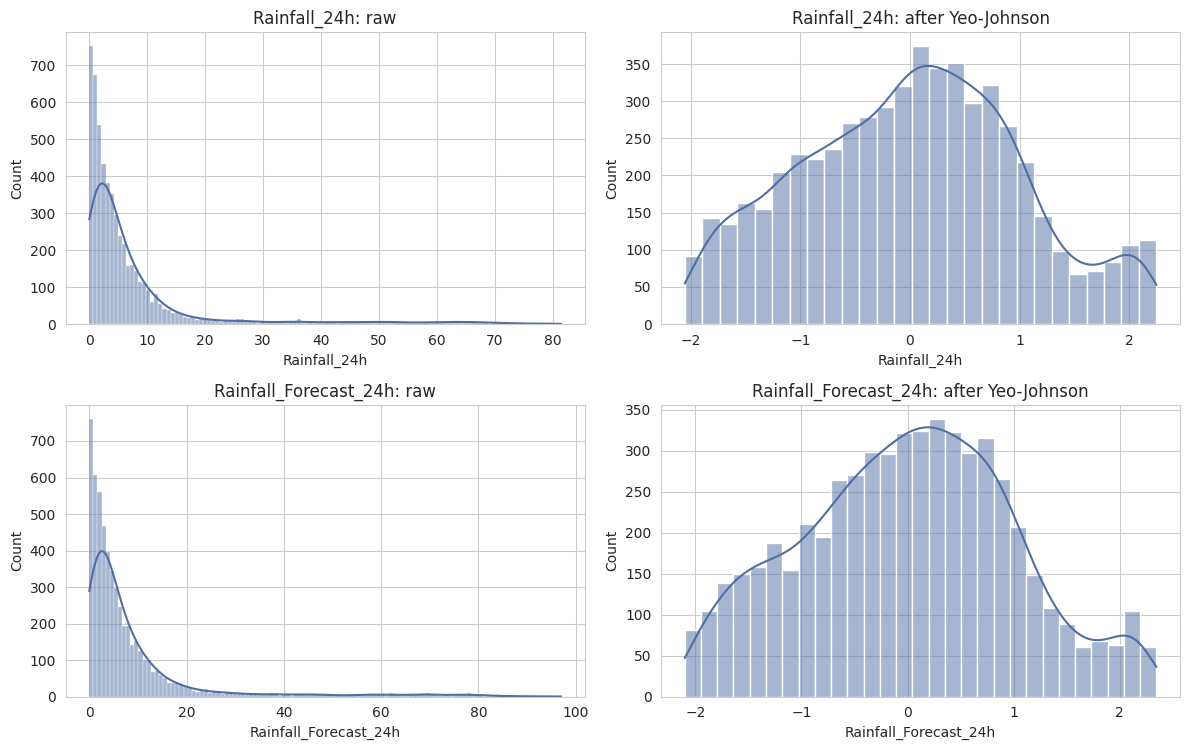

In [200]:
fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(12, 3.8 * len(skewed_cols)), squeeze=False)

for row, col in enumerate(skewed_cols):
    sns.histplot(X_train[col], kde=True, ax=axes[row, 0], color="#4F6EA4")
    axes[row, 0].set_title(f"{col}: raw")
    sns.histplot(X_train_preview[col], kde=True, ax=axes[row, 1], color="#4F6EA4")
    axes[row, 1].set_title(f"{col}: after Yeo-Johnson")

plt.tight_layout()
plt.show()

**How to read it:** skewness after the transform should be close to 0. The
fitted `lambda` is the strength of the transform: 1 means no change, and
values towards 0 are close to a log transform. Many rows with exactly or
nearly zero rain cannot be spread out by any transform, so a spike at the low
end may remain. That is expected.

### 6.7 Contract checks: behaving like the API will

Two checks simulate what the FastAPI service will send to the pipeline:

1. **A sparse app payload.** Only the required features are present, and
   every optional one is missing. The pipeline must still produce a complete
   row with no missing values. (The API itself must add any key the app
   *omits* as an empty value before calling the pipeline, because the
   pipeline needs every `FEATURES` column to exist.)
2. **A misspelled category.** `"sandy"` instead of `"Sandy"` must be
   rejected, not silently accepted.

In [201]:
REQUIRED_BY_APP = ["Soil_Type", "Soil_Moisture"]  # always present in an app payload

sparse_row = X_train[FEATURES].iloc[[0]].copy()
optional_cols = [c for c in FEATURES if c not in REQUIRED_BY_APP]
sparse_row[optional_cols] = np.nan

sparse_output = preview_preprocessor.transform(sparse_row)
assert not sparse_output.isna().any().any(), "Missing optional features were not filled"
print(f"Sparse payload ({len(optional_cols)} of {len(FEATURES)} features missing): transformed with no gaps.")

Sparse payload (8 of 10 features missing): transformed with no gaps.


In [202]:
misspelled_row = X_train[FEATURES].iloc[[0]].copy()
misspelled_row["Soil_Type"] = "sandy"

try:
    preview_preprocessor.transform(misspelled_row)
    print("PROBLEM: the misspelled label was accepted silently.")
except ValueError as error:
    print(f"Rejected as intended: {str(error)[:90]}...")

Rejected as intended: Found unknown categories ['sandy'] in column 0 during transform...


**Summary of section 6:**
- One preprocessor, built from `FEATURES`, imputes, transforms, scales and
  encodes every column. It is fitted inside each cross-validation fold, so
  nothing leaks.
- Rainfall's skew is corrected with Yeo-Johnson; numeric features are
  standardised; soil type is one-hot encoded.
- Missing optional features are filled with neutral training medians, and a
  misspelled category is rejected instead of silently ignored.
- `build_preprocessor()` gives every model in section 7 its own fresh copy.

## 7. Model comparison

**Goal:** find which *family* of algorithm suits this problem best, before
spending time on tuning (section 8).

**What stays fixed, so the comparison is fair:**

| Fixed element | Value | Why |
|---|---|---|
| Features | `FEATURES` (section 5) | Only the algorithm changes between rows. |
| Preprocessing | `build_preprocessor()` (section 6) | Each model gets its own fresh copy, fitted inside each fold. |
| Folds | `cv` from section 5.3 | Every model is scored on exactly the same 5 splits, so fold-by-fold differences can be compared directly (7.6). |
| Metric | macro-F1 (section 3.1) | Treats the four actions as equally important. Accuracy is recorded too, for reference. |
| Data | training set only | The test set stays untouched until section 9. |

**No SMOTE or other resampling.** The earlier draft added SMOTE to every
model. Section 3.1 showed the classes are perfectly balanced (25% each), so
there is nothing to rebalance. Synthetic rows would only add noise and
training time.

**Untuned settings.** Each model uses its library defaults or a common,
sensible value. Section 8 tunes only the best 2–3 families. Tuning all seven
would cost a lot of time, and the comparison here is about which approach
fits the data, not about the best possible settings.

### 7.1 One function to build and score every model

**Why:** if every model goes through the same two functions, no model can get
a different preprocessing step, different folds or a different metric by
accident.

- `make_model_pipeline` joins a fresh preprocessor and a fresh copy of the
  model (`clone`), so no fitted state carries over between experiments.
- `evaluate_model` runs 5-fold cross-validation and keeps the **per-fold**
  scores, plus the scores on each fold's own *training* data
  (`return_train_score=True`). The gap between the two measures overfitting
  (7.5).

In [203]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [204]:
def make_model_pipeline(model, features=None):
    """Fresh preprocessor + fresh copy of the model."""
    return Pipeline([
        ("preprocess", build_preprocessor(features)),
        ("model", clone(model)),
    ])

In [205]:
model_results = {}


def evaluate_model(name, model, features=None):
    """Cross-validate one model on the training set and record per-fold scores."""
    features = FEATURES if features is None else list(features)
    scores = cross_validate(
        make_model_pipeline(model, features), X_train[features], y_train,
        cv=cv, groups=cv_groups, scoring=["f1_macro", "accuracy"],
        return_train_score=True, n_jobs=-1,
    )
    model_results[name] = scores
    print(f"{name:28s} macro-F1 = {scores['test_f1_macro'].mean():.4f} "
          f"(+/- {scores['test_f1_macro'].std():.4f})  "
          f"fit {scores['fit_time'].mean():.1f}s/fold")
    return scores['test_f1_macro'].mean()

### 7.2 Baseline: what does guessing score?

**Why:** a score means little without a reference point. A `DummyClassifier`
ignores the features and guesses a class uniformly at random. Any real model
must clearly beat it; one that does not has learned nothing.

With four balanced classes, random guessing should land near **0.25**.

In [206]:
score_dummy = evaluate_model("Baseline (random guess)",
                             DummyClassifier(strategy="uniform", random_state=RANDOM_STATE))

Baseline (random guess)      macro-F1 = 0.2430 (+/- 0.0128)  fit 0.1s/fold


### 7.3 The candidate models

Seven families, chosen because each learns in a different way. If one of them
scores clearly higher, it tells us something about the *shape* of the
problem.

| Model | How it learns | Why it is a candidate | Starting settings |
|---|---|---|---|
| Logistic Regression | One weighted sum of features per class | Simple, fast, easy to explain. Shows how far a *linear* model gets. | defaults, `max_iter=2000` so it converges |
| K-Nearest Neighbours | Copies the majority label of the most similar past readings | No training; a check on whether "similar conditions → same action" holds. | `n_neighbors=15` (smooths out noisy labels) |
| Decision Tree | A sequence of yes/no thresholds | Readable rules a farmer could follow. | `max_depth=6`, so it stays readable and does not memorise |
| Random Forest | Averages many trees built on random subsets | Handles interactions and noise well. It is also the yardstick from section 5. | `n_estimators=300`, the same as section 5 |
| Gradient Boosting | Adds small trees one at a time, each fixing the last one's mistakes | Often the strongest on tabular data. | `HistGradientBoostingClassifier` defaults |
| Support Vector Machine | Finds the widest boundary between classes, curved with an RBF kernel | Strong on medium-sized data with scaled features (section 6). | RBF kernel defaults |
| Naive Bayes | Probabilities, assuming features are independent | A very fast reference; shows how much feature interactions matter. | defaults |

**Notes on two choices:**
- `HistGradientBoostingClassifier` is scikit-learn's faster implementation of
  gradient boosting. On 5,600 rows it trains in seconds, which keeps the
  section 8 search affordable.
- The SVM is trained **without** `probability=True`. That option runs an
  extra internal cross-validation and makes training about five times
  slower. It is not needed to compare scores. If the SVM is chosen and the
  app needs confidence values, section 8 switches it on.

In [207]:
CANDIDATE_MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}

In [208]:
for name, model in CANDIDATE_MODELS.items():
    evaluate_model(name, model)

Logistic Regression          macro-F1 = 0.4991 (+/- 0.0049)  fit 0.1s/fold
K-Nearest Neighbours         macro-F1 = 0.4610 (+/- 0.0172)  fit 0.1s/fold
Decision Tree                macro-F1 = 0.4733 (+/- 0.0146)  fit 0.1s/fold
Random Forest                macro-F1 = 0.4996 (+/- 0.0071)  fit 7.8s/fold
Gradient Boosting            macro-F1 = 0.4909 (+/- 0.0083)  fit 2.1s/fold
Support Vector Machine       macro-F1 = 0.5104 (+/- 0.0099)  fit 2.1s/fold
Naive Bayes                  macro-F1 = 0.4320 (+/- 0.0178)  fit 0.1s/fold


### 7.4 Results side by side

**What to read in the table:**
- `val_f1`: the mean macro-F1 on the held-out folds. This is the score that
  matters.
- `val_std`: how much it varies between folds. Two models whose scores differ
  by less than this are not clearly different (7.6 checks this properly).
- `val_accuracy`: with balanced classes it should sit close to macro-F1.
- `fit_s`: training time per fold. All of these are fast enough for an API,
  so time only matters if two models tie.

In [209]:
comparison = pd.DataFrame({
    name: {
        "val_f1": s["test_f1_macro"].mean(),
        "val_std": s["test_f1_macro"].std(),
        "train_f1": s["train_f1_macro"].mean(),
        "val_accuracy": s["test_accuracy"].mean(),
        "fit_s": s["fit_time"].mean(),
    }
    for name, s in model_results.items()
}).T.sort_values("val_f1", ascending=False)

comparison["vs_baseline"] = comparison["val_f1"] - score_dummy
comparison["vs_ceiling"] = comparison["val_f1"] - score_ceiling
comparison.round(4)

,val_f1,val_std,train_f1,val_accuracy,fit_s,vs_baseline,vs_ceiling
Support Vector Machine,0.5104,0.0099,0.6045,0.5136,2.0689,0.2675,-0.0062
Random Forest,0.4996,0.0071,1.0000,0.5048,7.8074,0.2567,-0.0170
Logistic Regression,0.4991,0.0049,0.5065,0.5079,0.1126,0.2562,-0.0175
Gradient Boosting,0.4909,0.0083,0.9870,0.4925,2.1100,0.2479,-0.0258
Decision Tree,0.4733,0.0146,0.5300,0.4727,0.1245,0.2304,-0.0433
K-Nearest Neighbours,0.4610,0.0172,0.5503,0.4630,0.0842,0.2181,-0.0556
Naive Bayes,0.4320,0.0178,0.4394,0.4539,0.1024,0.1890,-0.0847
Baseline (random guess),0.2430,0.0128,0.2559,0.2434,0.0694,0.0000,-0.2737


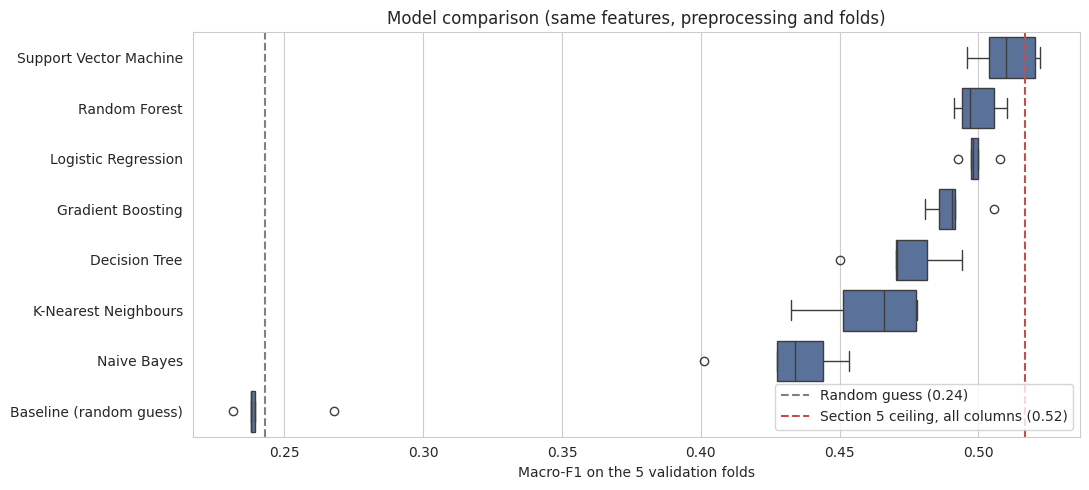

In [210]:
fold_scores = pd.DataFrame({name: s["test_f1_macro"] for name, s in model_results.items()})
fold_scores = fold_scores[comparison.index]  # best model first

plt.figure(figsize=(11, 5))
sns.boxplot(data=fold_scores, color="#4F6EA4", orient="h")
plt.axvline(score_dummy, color="grey", linestyle="--", label=f"Random guess ({score_dummy:.2f})")
plt.axvline(score_ceiling, color="#C0504D", linestyle="--",
            label=f"Section 5 ceiling, all columns ({score_ceiling:.2f})")
plt.xlabel("Macro-F1 on the 5 validation folds")
plt.title("Model comparison (same features, preprocessing and folds)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result: the SVM ranks first, and every real model beats chance by a wide margin.**

| Rank | Model | Macro-F1 | Reading |
|---|---|---|---|
| 1 | Support Vector Machine | 0.510 | Within **0.006** of the section 5 ceiling, which used all 25 columns. With 10 features it matches what a forest achieves with every column. |
| 2 | Random Forest | 0.500 | |
| 3 | Logistic Regression | 0.499 | As good as the forest, and the most stable (fold spread 0.005). |
| 4 | Gradient Boosting | 0.491 | |
| 5–7 | Decision Tree, KNN, Naive Bayes | 0.43–0.47 | Clearly weaker. |
| | Random guess | 0.243 | As expected for four balanced classes. |

**What the ranking says about the data:**
- **A straight-line model does as well as a forest of 300 trees.** The link
  between the features and the action is therefore mostly *linear*: more
  moisture, less irrigation, and so on. This matches section 5, where
  `Water_Stress_Index` turned out to be a weighted sum of the inputs
  (R² 0.99). The data generator most likely added noise to a near-linear
  rule. The SVM's curved boundary adds only one more point on top of that.
- **Naive Bayes is last among the real models** because it assumes features
  are independent. `Soil_Moisture` and `Historical_Soil_Moisture` are
  strongly related (section 3.6), so it counts the same evidence twice.
- **KNN suffers from noisy labels.** Neighbouring readings with near-identical
  conditions often carry different actions (the class overlap seen in
  section 3.5), so copying neighbours copies that noise.

### 7.5 Overfitting check: training score against validation score

**Why:** a model that scores much higher on the rows it learned from than on
unseen rows has memorised noise. It will do worse on a real farm than its
training score suggests.

**How to read the gap** (`train_f1 − val_f1`):

| Gap | Reading |
|---|---|
| below 0.05 | No meaningful overfitting. |
| 0.05 to 0.15 | Mild. Worth controlling in section 8. |
| above 0.15 | Strong. The model fits noise in the training labels. |

**One caution:** an untuned Random Forest grows every tree to full depth, so
its training score is close to 1.0 *by design*. A large gap there is
expected; the forest's averaging is what protects the validation score. For
those models the gap is a **tuning signal** (limit depth or leaf size in
section 8), not a reason to reject them. The decision is always made on the
**validation** score.

In [211]:
def gap_label(gap):
    if gap < 0.05:
        return "none"
    return "mild" if gap <= 0.15 else "strong"


overfit = comparison[["train_f1", "val_f1"]].copy()
overfit["gap"] = overfit["train_f1"] - overfit["val_f1"]
overfit["overfitting"] = overfit["gap"].apply(gap_label)
overfit.round(4)

,train_f1,val_f1,gap,overfitting
Support Vector Machine,0.6045,0.5104,0.0941,mild
Random Forest,1.0000,0.4996,0.5004,strong
Logistic Regression,0.5065,0.4991,0.0074,none
Gradient Boosting,0.9870,0.4909,0.4961,strong
Decision Tree,0.5300,0.4733,0.0566,mild
K-Nearest Neighbours,0.5503,0.4610,0.0893,mild
Naive Bayes,0.4394,0.4320,0.0074,none
Baseline (random guess),0.2559,0.2430,0.0130,none


**Result:**
- **Random Forest (1.00 → 0.50) and Gradient Boosting (0.99 → 0.49)
  memorise the training set completely.** They learn the label noise as if
  it were a pattern. They still validate reasonably, but this is the clearest
  room for tuning in section 8: larger leaves (`min_samples_leaf`), shallower
  trees, and for boosting a lower learning rate with stronger regularisation.
- **The SVM's gap of 0.09 is mild.** Its `C` (how strictly it fits the
  training rows) and `gamma` (how curved the boundary may be) are the
  natural settings to tune.
- **Logistic Regression has almost no gap (0.007).** It cannot overfit much,
  which is also why it cannot gain much from tuning.

### 7.6 Are the differences real?

**Why:** cross-validation scores vary from fold to fold. If the best model
beats the runner-up by 0.003 while the folds vary by 0.01, the "win" may be
luck.

**How:** every model was scored on the **same five folds**, so we can compare
them fold by fold (a *paired* comparison). For each model we take its score
minus the best model's score on each fold. If the mean difference is smaller
than its own fold-to-fold spread, or smaller than the 0.01 tolerance used in
section 5, the two models are **tied**.

This is more sensitive than comparing two overall averages, because the
difficulty of each fold cancels out.

In [212]:
best_name = comparison.index[0]

paired = pd.DataFrame({
    name: fold_scores[name] - fold_scores[best_name]
    for name in comparison.index if name != best_name
}).agg(["mean", "std"]).T.rename(columns={"mean": "mean_diff", "std": "std_diff"})

paired["tied_with_best"] = (paired["mean_diff"].abs() <= paired["std_diff"]) | (
    paired["mean_diff"].abs() <= TOLERANCE)

print(f"Best model: {best_name} ({comparison.loc[best_name, 'val_f1']:.4f})")
paired.round(4)

Best model: Support Vector Machine (0.5104)


,mean_diff,std_diff,tied_with_best
Random Forest,-0.0108,0.0067,False
Logistic Regression,-0.0113,0.0102,False
Gradient Boosting,-0.0196,0.0075,False
Decision Tree,-0.0371,0.0201,False
K-Nearest Neighbours,-0.0494,0.0151,False
Naive Bayes,-0.0785,0.0235,False
Baseline (random guess),-0.2675,0.0121,False


**Result: the SVM's lead is small but consistent.** It beats the Random
Forest by 0.011 and Logistic Regression by 0.011 on average. In both cases
the difference is larger than its fold-to-fold spread (0.007 and 0.010) and
just above the 0.01 tolerance, so it is not a lucky fold. It is still only
about one point, though. Tuning in section 8 could change the order, which is
why more than one family goes forward.

### 7.7 Sanity check: does the Random Forest reproduce section 5?

**Why:** the Random Forest here uses the same settings and the same folds as
the section 5 yardstick. Trees are not affected by scaling, and the
Yeo-Johnson transform keeps the order of values, so the section 6
preprocessing should hardly change what it learns. The scores will not be
*identical*: the columns now arrive in a different order, and a forest picks
random subsets of columns, so it grows slightly different trees. Its score
should still match the section 5 score for the final feature set to within
about one fold standard deviation (≈ 0.01).

A larger difference would mean something is wrong in the preprocessing: a
column dropped by mistake, for example, or a different imputation.

In [213]:
section5_reference = {
    (True, True): score_no_both, (True, False): score_no_weak,
    (False, True): score_no_crop, (False, False): score_base,
}[(DROP_WEAK, DROP_CROP)]

rf_now = comparison.loc["Random Forest", "val_f1"]
print(f"Random Forest, section 5 yardstick: {section5_reference:.4f}")
print(f"Random Forest, section 6 pipeline:  {rf_now:.4f}")
print(f"Difference: {rf_now - section5_reference:+.4f}")

Random Forest, section 5 yardstick: 0.5029
Random Forest, section 6 pipeline:  0.4996
Difference: -0.0033


**Result:** −0.003, well within one fold standard deviation. The section 6
preprocessing does what it should, and the section 5 conclusions carry over
to the new pipeline.

### 7.8 Shortlist and feature re-check

**Shortlist:** the **three** best families by validation macro-F1 go on to
tuning in section 8. Three is a compromise: enough to give tuning a chance
to change the ranking, few enough to keep the search affordable.

**Feature re-check:** section 5 chose features with a Random Forest. Another
algorithm might make use of a feature the forest ignored. For each
shortlisted model, we therefore re-run it with **all features the app can
send** (`APP_FEATURES`, 23 columns) and compare.

- If the longer list helps a model by more than the 0.01 tolerance, section 5
  was too strict for that model, and its feature list is revisited.
- If not, the 10 features hold for every finalist. That supports the
  section 5 choice beyond the one model that made it.

In [214]:
SHORTLIST = list(comparison.drop(index="Baseline (random guess)").index[:3])
print(f"Shortlist for section 8: {SHORTLIST}\n")

recheck = {}
for name in SHORTLIST:
    score_all = evaluate_model(f"{name} (all app features)", CANDIDATE_MODELS[name], APP_FEATURES)
    recheck[name] = {
        "final_features": comparison.loc[name, "val_f1"],
        "all_app_features": score_all,
    }

recheck = pd.DataFrame(recheck).T
recheck["gain_from_more_features"] = recheck["all_app_features"] - recheck["final_features"]
recheck["revisit_features"] = recheck["gain_from_more_features"] > TOLERANCE
recheck.round(4)

Shortlist for section 8: ['Support Vector Machine', 'Random Forest', 'Logistic Regression']

Support Vector Machine (all app features) macro-F1 = 0.4988 (+/- 0.0165)  fit 2.9s/fold
Random Forest (all app features) macro-F1 = 0.4964 (+/- 0.0095)  fit 9.8s/fold
Logistic Regression (all app features) macro-F1 = 0.4907 (+/- 0.0011)  fit 0.2s/fold


,final_features,all_app_features,gain_from_more_features,revisit_features
Support Vector Machine,0.5104,0.4988,-0.0117,False
Random Forest,0.4996,0.4964,-0.0032,False
Logistic Regression,0.4991,0.4907,-0.0085,False


**Result: more features make every finalist *worse*.** Adding the 13 features
dropped in section 5 costs the SVM 0.012, Logistic Regression 0.009 and the
Random Forest 0.003. None of the three needs its feature list revisited.

This is stronger evidence than section 5 alone: three algorithms that learn
in very different ways agree that the extra columns add only noise. The SVM
loses the most because its kernel measures distances between readings. Every
irrelevant column adds random distance and blurs which readings are
genuinely similar.

**Thesis wording:** *The 10-feature set was selected with a Random Forest and
confirmed with two further algorithms: adding the remaining 13 collectable
features reduced macro-F1 for all three (−0.003 to −0.012).*

**Summary of section 7:**
- Every model beats chance (0.24) clearly. The best, an untuned **SVM at
  0.510**, sits within 0.006 of the dataset ceiling from section 5.
- Linear and non-linear models score almost the same, so the problem is close
  to linear plus label noise. Expect gains from tuning of about 0.01, not 0.1.
- The tree ensembles memorise the training data (train F1 ≈ 1.0); their
  tuning should focus on regularisation.
- The 10 features are confirmed by three algorithms.
- **Shortlist for section 8:** SVM, Random Forest and Logistic Regression.
  **Gradient Boosting is added as a fourth.** It is only 0.02 behind, it has
  the largest overfitting gap (the most room to improve), it is cheap to
  train, and boosted trees are often the strongest family on tabular data
  once tuned. Leaving it out on untuned defaults would be an unfair test.
- **For the app:** if the SVM wins, it must be trained with
  `probability=True` to return a confidence value. Section 8 compares it
  with that option on.

## 8. Hyperparameter tuning

**What tuning is:** every algorithm has settings that are chosen *before*
training (hyperparameters), such as how deep a tree may grow or how strictly
an SVM fits the training rows. Section 7 used defaults. Here we search for
the settings that give the best cross-validated macro-F1.

**Which models:** the four from the section 7 summary.

| Model | Section 7 score | What tuning should fix |
|---|---|---|
| Support Vector Machine | 0.510 | Mild overfitting (gap 0.09): balance `C` and `gamma`. |
| Random Forest | 0.500 | Memorises the training set (train F1 1.00): larger leaves, limited depth. |
| Logistic Regression | 0.499 | Almost nothing to fix; tuned so the comparison is fair. |
| Gradient Boosting | 0.491 | Memorises the training set (train F1 0.99): slower learning, regularisation. |

The earlier draft tuned **only** Logistic Regression and then compared it
against untuned models. That favours whichever model happens to be tuned.
Here every finalist gets the same search effort, folds and metric.

**Expectation:** section 7 showed the problem is close to linear plus label
noise, and the best model already sits within 0.006 of the section 5
ceiling. Gains of about 0.01 are realistic; anything near 0.05 would be
suspicious.

### 8.1 Search method: randomised search, not a full grid

**Why not a grid:** a grid tries every combination. With five settings of
four values each, that is 4⁵ = 1,024 combinations × 5 folds. Most of that
time is spent varying settings that barely matter.

**Randomised search** (`RandomizedSearchCV`) draws a fixed number of random
combinations from ranges we define. For the same time budget, it tries many
more *distinct* values of the settings that do matter (Bergstra and Bengio,
2012).

**Decisions:**

| Choice | Value | Reason |
|---|---|---|
| Combinations per model | 20–30 (`SEARCH_ITERATIONS`) | Enough to find the good region; the whole section runs in about 10–15 minutes on Colab. Lower the numbers for a quick run. |
| Ranges for `C`, `gamma`, learning rate | log-uniform | These settings work on a multiplicative scale: going from 0.01 to 0.1 matters as much as 1 to 10. A log scale samples both ends equally. |
| Folds, metric | `cv`, macro-F1 | Identical to sections 5 and 7, so scores are directly comparable. |
| `return_train_score=True` | | Shows whether tuning reduced the overfitting gap. |
| `refit=True` | | After the search, the best settings are retrained on the whole training set. That model goes to section 9. |
| `random_state` | `RANDOM_STATE` | The same combinations are drawn on every run. |

In [215]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

SEARCH_ITERATIONS = {
    "Support Vector Machine": 30,
    "Random Forest": 20,
    "Logistic Regression": 20,
    "Gradient Boosting": 30,
}
TUNED_FAMILIES = list(SEARCH_ITERATIONS)

### 8.2 The search ranges

Each range is centred on the default from section 7 and wide enough to
reach both a much simpler and a much more flexible model. `model__` is
scikit-learn's way of addressing a setting of the `model` step inside the
pipeline.

| Model | Setting | Range | What it controls |
|---|---|---|---|
| SVM | `C` | 0.1 – 100 | How strictly the boundary must fit the training rows. High values overfit. |
| | `gamma` | 0.001 – 1 | How curved the boundary may be. High values follow individual rows. The default (`"scale"`, ≈ 0.08 here) lies inside the range. |
| Random Forest | `max_depth` | 6 – 16, or unlimited | How many questions a tree may ask. |
| | `min_samples_leaf` | 1 – 40 | Rows needed to form a leaf. Larger leaves average out label noise, which is the main fix for memorisation. |
| | `max_features` | `sqrt`, 30%, 50% | Columns each split may consider. Fewer make the trees more varied. |
| Logistic Regression | `C` | 0.001 – 100 | Inverse strength of the penalty on large weights. |
| Gradient Boosting | `learning_rate` | 0.01 – 0.3 | How much each new tree corrects. Lower is slower but steadier. |
| | `max_iter` | 100 – 400 | Number of trees. |
| | `max_leaf_nodes` | 7 – 63 | Size of each tree. |
| | `min_samples_leaf` | 10 – 100 | As for the forest. |
| | `l2_regularization` | 0.001 – 10 | Penalty that shrinks each tree's corrections. |

**Fixed, not tuned:**
- The forest keeps **300 trees.** More trees never make a forest less
  accurate; they only cost time. 300 is already past the point where scores
  stop changing.
- The SVM keeps the **RBF kernel.** Logistic Regression already represents
  the linear case, so a linear SVM would add little.

In [216]:
SEARCH_SPACES = {
    "Support Vector Machine": {
        "model__C": loguniform(0.1, 100),
        "model__gamma": loguniform(1e-3, 1),
    },
    "Random Forest": {
        "model__max_depth": [6, 8, 10, 12, 16, None],
        "model__min_samples_leaf": [1, 2, 5, 10, 20, 40],
        "model__max_features": ["sqrt", 0.3, 0.5],
    },
    "Logistic Regression": {
        "model__C": loguniform(1e-3, 100),
    },
    "Gradient Boosting": {
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__max_iter": [100, 200, 300, 400],
        "model__max_leaf_nodes": [7, 15, 31, 63],
        "model__min_samples_leaf": [10, 20, 50, 100],
        "model__l2_regularization": loguniform(1e-3, 10),
    },
}
assert set(SEARCH_SPACES) == set(TUNED_FAMILIES)

### 8.3 Run the searches

Each search starts from the section 7 model (`CANDIDATE_MODELS`) inside a
fresh pipeline, so the only thing that differs from section 7 is the
settings. This cell is the slow one; each model prints its result when it
finishes.

In [217]:
searches = {}

for name in TUNED_FAMILIES:
    search = RandomizedSearchCV(
        make_model_pipeline(CANDIDATE_MODELS[name]),
        param_distributions=SEARCH_SPACES[name],
        n_iter=SEARCH_ITERATIONS[name],
        scoring="f1_macro", cv=cv, refit=True, return_train_score=True,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    search.fit(X_train[FEATURES], y_train, groups=cv_groups)
    searches[name] = search
    print(f"{name:24s} best macro-F1 = {search.best_score_:.4f}  "
          f"(section 7 default: {comparison.loc[name, 'val_f1']:.4f})")

Support Vector Machine   best macro-F1 = 0.5147  (section 7 default: 0.5104)
Random Forest            best macro-F1 = 0.5083  (section 7 default: 0.4996)
Logistic Regression      best macro-F1 = 0.4996  (section 7 default: 0.4991)
Gradient Boosting        best macro-F1 = 0.5142  (section 7 default: 0.4909)


### 8.4 What did tuning change?

**What to read:**
- `gain`: tuned score minus the section 7 default. This is what the search
  bought.
- `train_f1` and `gap`: whether the overfitting from section 7.5 shrank.
- `near_best`: how many of the tried combinations score within 0.01 of the
  best. A high count means the model is **robust**: many settings work, so
  the exact values matter little. A count of 1 means the best result
  depends on one lucky combination and may not hold on new data.

In [218]:
def best_row(search):
    """Per-fold and summary scores of the best combination in a search."""
    results = pd.DataFrame(search.cv_results_)
    return results.loc[search.best_index_], results


tuning_rows, tuned_fold_scores = {}, {}
for name, search in searches.items():
    best, results = best_row(search)
    tuned_fold_scores[name] = [best[f"split{k}_test_score"] for k in range(cv.get_n_splits())]
    tuning_rows[name] = {
        "default_f1": comparison.loc[name, "val_f1"],
        "tuned_f1": best["mean_test_score"],
        "tuned_std": best["std_test_score"],
        "gain": best["mean_test_score"] - comparison.loc[name, "val_f1"],
        "train_f1": best["mean_train_score"],
        "gap": best["mean_train_score"] - best["mean_test_score"],
        "near_best": int((results["mean_test_score"] >= best["mean_test_score"] - TOLERANCE).sum()),
        "tried": len(results),
        "fit_s": best["mean_fit_time"],
    }

tuning_summary = pd.DataFrame(tuning_rows).T.sort_values("tuned_f1", ascending=False)
tuned_fold_scores = pd.DataFrame(tuned_fold_scores)[tuning_summary.index]
tuning_summary.round(4)

,default_f1,tuned_f1,tuned_std,gain,train_f1,gap,near_best,tried,fit_s
Support Vector Machine,0.5104,0.5147,0.0121,0.0042,0.5430,0.0283,13.0,30.0,2.1923
Gradient Boosting,0.4909,0.5142,0.0088,0.0233,0.6957,0.1816,6.0,30.0,3.6994
Random Forest,0.4996,0.5083,0.0063,0.0087,0.7458,0.2375,13.0,20.0,10.0807
Logistic Regression,0.4991,0.4996,0.0052,0.0004,0.5060,0.0064,16.0,20.0,0.2739


**Result: tuning helped the tree models most, and the top two are now level.**

| Model | Default → tuned | Gain | Train–validation gap | Robust? (`near_best`) |
|---|---|---|---|---|
| Support Vector Machine | 0.510 → **0.515** | +0.004 | 0.09 → 0.03 | 13 of 30 |
| Gradient Boosting | 0.491 → **0.514** | **+0.023** | 0.50 → 0.18 | 6 of 30 |
| Random Forest | 0.500 → 0.508 | +0.009 | 0.50 → 0.24 | 13 of 20 |
| Logistic Regression | 0.499 → 0.500 | +0.000 | 0.01 → 0.01 | 16 of 20 |

- **As expected, the gains are small** (at most 0.023). The best tuned score,
  0.515, is now within **0.002** of the section 5 ceiling (0.517). That
  ceiling used all 25 columns, including the two the app cannot send.
- **Gradient Boosting gained the most** because its defaults memorised the
  training data. Slower learning and small trees roughly halved its
  overfitting gap.
- **The SVM barely moved.** Its default was already close to its best, and
  13 of 30 combinations score within 0.01 of the top. That makes it the most
  robust of the strong models.
- **Logistic Regression cannot improve** because it has almost no
  flexibility to tune. Its ceiling here is about 0.50.
- **Gradient Boosting is the least robust:** only 6 of 30 combinations come
  close to its best. Its good region is narrower, so its settings matter
  more (see the boundary note below).

In [219]:
for name, search in searches.items():
    params = {key.replace("model__", ""): value for key, value in search.best_params_.items()}
    readable = ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())
    print(f"{name:24s} {readable}")

Support Vector Machine   C=31.43, gamma=0.004335
Random Forest            min_samples_leaf=10, max_features=0.5, max_depth=12
Logistic Regression      C=0.1445
Gradient Boosting        l2_regularization=0.02673, learning_rate=0.026, max_iter=400, max_leaf_nodes=7, min_samples_leaf=10


**Reading the best settings:**
- **SVM: `C` = 31, `gamma` = 0.004.** A very small `gamma` gives an almost
  flat, gently curved boundary, and the high `C` lets it fit that boundary
  closely. This is the "nearly linear" shape from section 7, with just enough
  curvature to beat Logistic Regression.
- **Random Forest: `min_samples_leaf` = 10, `max_depth` = 12.** Requiring 10
  rows per leaf stops trees from memorising single noisy readings. That cut
  the train score from 1.00 to 0.75.
- **Gradient Boosting:** 400 small trees (7 leaves each), a low learning rate
  of 0.026, and 10 rows per leaf.
- **Boundary note:** two Gradient Boosting settings landed on the **edge** of
  their ranges: `max_iter` = 400 (the maximum) and `max_leaf_nodes` = 7 (the
  minimum). When the best value sits on an edge, the true optimum may lie
  beyond it, such as more or smaller trees. Section 8.8 checks this.

### 8.5 Where is the SVM's good region?

**Why:** the SVM led section 7, and its two settings interact: a curved
boundary (high `gamma`) needs a gentle fit (low `C`), and the reverse.
Plotting every combination tried shows whether the best score sits in a
broad, safe region or on a narrow ridge. A broad region means the result is
not fragile.

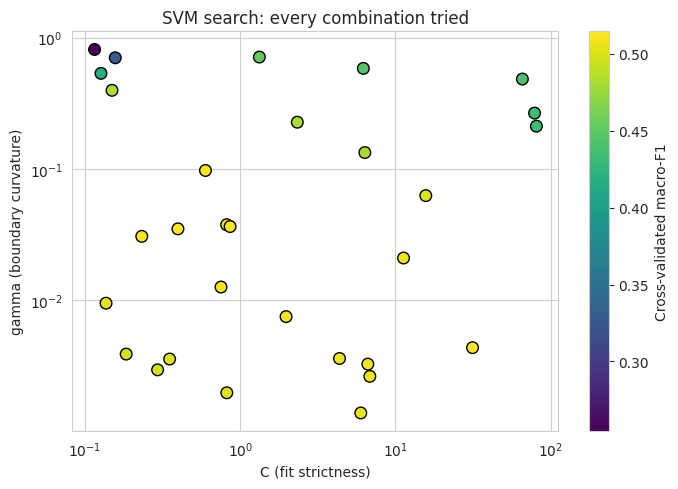

In [220]:
svm_results = pd.DataFrame(searches["Support Vector Machine"].cv_results_)

plt.figure(figsize=(7, 5))
points = plt.scatter(svm_results["param_model__C"].astype(float),
                     svm_results["param_model__gamma"].astype(float),
                     c=svm_results["mean_test_score"], cmap="viridis", s=70, edgecolor="black")
plt.xscale("log")
plt.yscale("log")
plt.colorbar(points, label="Cross-validated macro-F1")
plt.xlabel("C (fit strictness)")
plt.ylabel("gamma (boundary curvature)")
plt.title("SVM search: every combination tried")
plt.tight_layout()
plt.show()

### 8.6 Choosing the final model

**Rule:** the best tuned score wins, **unless** a simpler model is tied with
it. "Tied" is the same paired-fold test as in section 7.6: the mean
difference is no larger than its fold-to-fold spread, or no larger than the
0.01 tolerance.

**Why prefer the simpler model when tied:** a difference that small is
noise, and it is unlikely to repeat on the test set or on real farms. The
simpler model is cheaper to serve, smaller to store, and easier to explain
to a farmer or an examiner. It also has fewer settings that could have been
fitted to the training folds by chance.

**Simplicity order** (simplest first), judged on three things the app cares
about: how easy the model is to explain, the size of the saved file, and
prediction speed:

| Order | Model | Reason |
|---|---|---|
| 1 | Logistic Regression | One weight per feature and class: fully readable, tiny file, instant. |
| 2 | Gradient Boosting | Small trees, a compact file, fast predictions. |
| 3 | Support Vector Machine | Stores thousands of training rows (support vectors); prediction compares each request with them. |
| 4 | Random Forest | 300 full trees: the largest file, often tens of megabytes. |

**About selection bias:** picking the best of four tuned scores slightly
flatters the winner, because part of its lead can be luck on these five
folds. That is why section 9 scores the chosen model **once** on the untouched
test set, which gives the unbiased estimate.

In [221]:
SIMPLICITY_ORDER = ["Logistic Regression", "Gradient Boosting", "Support Vector Machine", "Random Forest"]

top_name = tuning_summary.index[0]
tie_check = pd.DataFrame({
    name: tuned_fold_scores[name] - tuned_fold_scores[top_name] for name in tuning_summary.index
}).agg(["mean", "std"]).T.rename(columns={"mean": "mean_diff", "std": "std_diff"})
tie_check["tied_with_best"] = (tie_check["mean_diff"].abs() <= tie_check["std_diff"].fillna(0)) | (
    tie_check["mean_diff"].abs() <= TOLERANCE)

tied = [name for name in SIMPLICITY_ORDER if tie_check.loc[name, "tied_with_best"]]
FINAL_MODEL_NAME = tied[0]  # the top model is always tied with itself

print(f"Highest tuned score: {top_name}")
print(f"Tied with it: {tied}")
print(f"Final model: {FINAL_MODEL_NAME}")
tie_check.round(4)

Highest tuned score: Support Vector Machine
Tied with it: ['Gradient Boosting', 'Support Vector Machine', 'Random Forest']
Final model: Gradient Boosting


,mean_diff,std_diff,tied_with_best
Support Vector Machine,0.0000,0.0000,True
Gradient Boosting,-0.0005,0.0201,True
Random Forest,-0.0063,0.0104,True
Logistic Regression,-0.0151,0.0148,False


**Result: Gradient Boosting is the final model.**

- The SVM has the highest score, but Gradient Boosting is only **0.0005**
  behind. That is a tie by any standard: fold-to-fold variation is 40 times
  larger. The Random Forest also ties (−0.006). Logistic Regression does not
  (−0.015).
- Among the tied models, the rule picks the simplest: **Gradient Boosting.**

**Why that is a good outcome for the app, beyond the rule:**

| | Gradient Boosting | SVM |
|---|---|---|
| Confidence values | Built in, always consistent with the label | Needs a separate calibration step, which can disagree with the label |
| Prediction cost | 400 small trees: microseconds | Compares each request with thousands of stored training rows |
| Explaining a prediction (section 10) | Fast, exact SHAP values for trees | Slow, approximate SHAP values |
| Saved file | Small | Contains part of the training data |

**One observation:** the fold-by-fold difference between the two models
varies a lot (spread 0.020), even though the average difference is almost
zero. They win on *different* folds, which means they make partly different
mistakes. Combining them (a voting ensemble) could gain a little. But the
remaining room below the dataset ceiling is about 0.002, so it would add
complexity for no meaningful benefit. It is not pursued.

### 8.7 The final pipeline

`RandomizedSearchCV` has already retrained the best settings on the whole
training set (`refit=True`), so `final_pipeline` is ready for section 9.

**Confidence values for the app.** The app will show how sure the model is,
which needs `predict_proba`. Three of the four families provide it directly.
An SVM does not, unless it is trained with `probability=True`. That option
fits an extra calibration step (Platt scaling) on top of the same boundary.
The label from `predict()` does not change.

There is one catch: with an SVM, the most probable class from
`predict_proba` can occasionally differ from `predict()`, because the
calibration is fitted separately. The check below counts how often that
happens, so section 11 can decide which output the API shows.

In [222]:
final_pipeline = searches[FINAL_MODEL_NAME].best_estimator_

if FINAL_MODEL_NAME == "Support Vector Machine":
    labels_before = final_pipeline.predict(X_train[FEATURES])
    final_pipeline.set_params(model__probability=True, model__random_state=RANDOM_STATE)
    final_pipeline.fit(X_train[FEATURES], y_train)
    labels_after = final_pipeline.predict(X_train[FEATURES])
    print(f"Labels unchanged by probability=True: {(labels_before == labels_after).mean():.1%}")

probabilities = final_pipeline.predict_proba(X_train[FEATURES])
most_probable = final_pipeline.classes_[probabilities.argmax(axis=1)]
agreement = (most_probable == final_pipeline.predict(X_train[FEATURES])).mean()
print(f"predict() agrees with the most probable class on {agreement:.1%} of training rows")
print(f"Classes in model order: {list(final_pipeline.classes_)}")

predict() agrees with the most probable class on 100.0% of training rows
Classes in model order: ['High', 'Low', 'Medium', 'No_Irrigation']


**Result:** Gradient Boosting's `predict()` and its most probable class agree
on **100%** of rows, as expected for a model with built-in probabilities. The
API can return the label together with its probability as the confidence
value; the two will never contradict each other. The SVM calibration step
was not needed.

### 8.8 Boundary check: were the search ranges wide enough?

**Why:** two of Gradient Boosting's best settings landed on the edge of their
ranges in 8.2: `max_iter` = 400 (the largest value allowed) and
`max_leaf_nodes` = 7 (the smallest). A search can only find values inside
the range it is given. If the best value is on an edge, the true optimum may
lie beyond it, so the search might have stopped short.

**How:** a small **grid** that continues past both edges, so each setting is
tested on both sides of the old limit:

| Setting | Old range | Boundary grid |
|---|---|---|
| `max_iter` (number of trees) | 100 – 400 | 400, 600, 800 |
| `max_leaf_nodes` (tree size) | 7 – 63 | 3, 5, 7 |

The other three settings (`learning_rate`, `min_samples_leaf`,
`l2_regularization`) stay at their tuned values. That way any change in
score comes from the two edge settings alone. A full grid fits here because
it is only 3 × 3 = 9 combinations.

**Decision rule:** the new settings replace the old ones only if they score
more than the 0.01 tolerance higher. Otherwise the old model stays, and the
edge is explained as a **plateau**: the score has stopped changing, so
pushing further buys nothing.

The check applies only when Gradient Boosting is the final model; for any
other model the cell skips itself.

In [ ]:
from sklearn.model_selection import GridSearchCV

boundary_search = None

if FINAL_MODEL_NAME == "Gradient Boosting":
    boundary_grid = {
        "model__max_iter": [400, 600, 800],
        "model__max_leaf_nodes": [3, 5, 7],
    }
    tuned_settings = {key: value for key, value in searches[FINAL_MODEL_NAME].best_params_.items()
                      if key not in boundary_grid}

    boundary_search = GridSearchCV(
        make_model_pipeline(CANDIDATE_MODELS[FINAL_MODEL_NAME]).set_params(**tuned_settings),
        param_grid=boundary_grid, scoring="f1_macro", cv=cv,
        refit=True, return_train_score=True, n_jobs=-1,
    )
    boundary_search.fit(X_train[FEATURES], y_train, groups=cv_groups)
else:
    print(f"Final model is {FINAL_MODEL_NAME}; boundary check not needed.")

**Reading the grid:** each cell is the cross-validated macro-F1 for one
combination. The old best sits at 400 trees and 7 leaves. If the scores keep
rising towards a corner beyond it (more trees, or fewer leaves), the old
range was too narrow. If they level off, it is a plateau.

In [ ]:
if boundary_search is not None:
    boundary_results = pd.DataFrame(boundary_search.cv_results_)
    boundary_table = boundary_results.pivot(index="param_model__max_iter",
                                            columns="param_model__max_leaf_nodes",
                                            values="mean_test_score")
    boundary_table.index.name, boundary_table.columns.name = "max_iter", "max_leaf_nodes"
    display(boundary_table.round(4))

In [ ]:
if boundary_search is not None:
    old_score = searches[FINAL_MODEL_NAME].best_score_
    new_score = boundary_search.best_score_
    new_best = {key.replace("model__", ""): value for key, value in boundary_search.best_params_.items()}

    ADOPT_BOUNDARY = new_score > old_score + TOLERANCE
    if ADOPT_BOUNDARY:
        final_pipeline = boundary_search.best_estimator_

    print(f"Old best (8.3):        {old_score:.4f}")
    print(f"Best in boundary grid: {new_score:.4f} with {new_best}")
    print(f"Difference: {new_score - old_score:+.4f}  ->  new settings adopted: {ADOPT_BOUNDARY}")

final_settings = {key.replace("model__", ""): value
                  for key, value in final_pipeline.named_steps["model"].get_params().items()
                  if f"model__{key}" in SEARCH_SPACES[FINAL_MODEL_NAME]}
print(f"\nFinal {FINAL_MODEL_NAME} settings: {final_settings}")

**Conclusion** (interpreted once the notebook has been run on the real
data): if `ADOPT_BOUNDARY` is `False`, the original search was wide enough
and its edge values sit on a plateau. If it is `True`, `final_pipeline` now
holds the improved settings. Either way, `final_settings` above is the model
that goes to section 9.

**Summary of section 8:**
- Four finalists were tuned with the same randomised search. The gains were
  small (+0.000 to +0.023), as section 7 predicted, and the best scores now
  sit at the dataset ceiling.
- **Final model: Gradient Boosting** (`HistGradientBoostingClassifier`) with
  a cross-validated macro-F1 of **0.514**. It is tied with the SVM (0.515)
  and chosen as the simpler, faster and more explainable of the two.
- Its overfitting gap fell from 0.50 to 0.18. Its probabilities are
  consistent with its labels.
- Two of its settings sat on the edge of the search range; the boundary
  check in 8.8 tests past both edges before section 9.
- `final_pipeline` (preprocessing and model, retrained on all 5,600 training
  rows) goes to section 9 for the one-time test-set evaluation.